# Fruit and Vegetable Image Recognition - Data Pipeline

In [ ]:
import kagglehub
path = kagglehub.dataset_download("kritikseth/fruit-and-vegetable-image-recognition")

print(f"Dataset downloaded to: {path}")

100%|██████████| 1.98G/1.98G [00:21<00:00, 100MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/kritikseth/fruit-and-vegetable-image-recognition/versions/8


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import cv2
from collections import Counter, defaultdict
import warnings
warnings.filterwarnings('ignore')

# Set style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

print("=" * 60)
print("FRUIT & VEGETABLE DATA PIPELINE")
print("=" * 60)

FRUIT & VEGETABLE DATA PIPELINE


## 1. Data Collection

In [ ]:
print("\n" + "=" * 60)
print("1. DATA COLLECTION")
print("=" * 60)

# The dataset path is already determined by kagglehub.dataset_download in a previous cell.
# The `path` variable is '/kaggle/input/fruit-and-vegetable-image-recognition'.
# The actual dataset files (train, test, validation) are directly within this directory.
BASE_PATH = path

if BASE_PATH is None or not os.path.exists(BASE_PATH):
    print("ERROR: Could not find dataset path. Please check the dataset location.")
    print(f"Expected base path: {BASE_PATH}")
    print("Available directories in /kaggle/input:")
    if os.path.exists('/kaggle/input'):
        for d in os.listdir('/kaggle/input'):
            print(f"  - {d}")
    raise FileNotFoundError("Dataset not found or path is invalid")

TRAIN_DIR = os.path.join(BASE_PATH, 'train')
TEST_DIR = os.path.join(BASE_PATH, 'test')
VAL_DIR = os.path.join(BASE_PATH, 'validation')

print(f"Base Path: {BASE_PATH}")
print(f"Train Dir exists: {os.path.exists(TRAIN_DIR)}")
print(f"Test Dir exists: {os.path.exists(TEST_DIR)}")
print(f"Val Dir exists: {os.path.exists(VAL_DIR)}")

# Get class names
class_names = sorted([d for d in os.listdir(TRAIN_DIR)
                      if os.path.isdir(os.path.join(TRAIN_DIR, d))])
NUM_CLASSES = len(class_names)

print(f"\nTotal Classes: {NUM_CLASSES}")
print(f"First 10 Classes: {class_names[:10]}")
print(f"Last 10 Classes: {class_names[-10:]}")


1. DATA COLLECTION
Base Path: /root/.cache/kagglehub/datasets/kritikseth/fruit-and-vegetable-image-recognition/versions/8
Train Dir exists: True
Test Dir exists: True
Val Dir exists: True

Total Classes: 36
First 10 Classes: ['apple', 'banana', 'beetroot', 'bell pepper', 'cabbage', 'capsicum', 'carrot', 'cauliflower', 'chilli pepper', 'corn']
Last 10 Classes: ['pomegranate', 'potato', 'raddish', 'soy beans', 'spinach', 'sweetcorn', 'sweetpotato', 'tomato', 'turnip', 'watermelon']


## 2. Data Exploration Functions

In [ ]:
print("\n" + "=" * 60)
print("2. DATA EXPLORATION FUNCTIONS")
print("=" * 60)

def get_image_info(image_path):
    """Get detailed info about an image"""
    try:
        with Image.open(image_path) as img:
            return {
                'size': img.size,
                'mode': img.mode,
                'format': img.format,
                'width': img.width,
                'height': img.height
            }
    except Exception as e:
        return None

def analyze_directory(directory_path, split_name):
    """Analyze all images in a directory"""
    data = []

    if not os.path.exists(directory_path):
        print(f"Warning: Directory {directory_path} does not exist")
        return pd.DataFrame()

    for class_name in sorted(os.listdir(directory_path)):
        class_path = os.path.join(directory_path, class_name)
        if not os.path.isdir(class_path):
            continue

        images = [f for f in os.listdir(class_path)
                 if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.gif'))]

        for img_name in images:
            img_path = os.path.join(class_path, img_name)
            info = get_image_info(img_path)

            if info:
                data.append({
                    'split': split_name,
                    'class': class_name,
                    'filename': img_name,
                    'path': img_path,
                    'width': info['width'],
                    'height': info['height'],
                    'channels': info['mode'],
                    'format': info['format']
                })

    return pd.DataFrame(data)


2. DATA EXPLORATION FUNCTIONS


## 3. EDA - Exploratory Data Analysis

In [ ]:
print("\n" + "=" * 60)
print("3. EXPLORATORY DATA ANALYSIS (EDA)")
print("=" * 60)

# Analyze all splits
print("\nAnalyzing images...")
train_df = analyze_directory(TRAIN_DIR, 'train')
test_df = analyze_directory(TEST_DIR, 'test')
val_df = analyze_directory(VAL_DIR, 'validation')

# Check if data was loaded
if len(train_df) == 0:
    print("ERROR: No training data loaded. Checking directory structure...")
    print(f"Train directory contents: {os.listdir(TRAIN_DIR) if os.path.exists(TRAIN_DIR) else 'Not found'}")
    raise ValueError("No training data found")

# Combine all data
full_df = pd.concat([train_df, test_df, val_df], ignore_index=True)

print(f"\nTotal Images Analyzed: {len(full_df)}")
print(f"\nSplit Distribution:")
split_counts = full_df['split'].value_counts()
for split, count in split_counts.items():
    print(f"  {split}: {count} images ({count/len(full_df)*100:.1f}%)")

# Class distribution per split
class_dist = full_df.groupby(['split', 'class']).size().reset_index(name='count')
class_dist_pivot = class_dist.pivot(index='class', columns='split', values='count').fillna(0)

print(f"\nClass Distribution Summary:")
if 'train' in class_dist_pivot.columns:
    train_counts = class_dist_pivot['train']
    print(f"  Train - Min: {train_counts.min()}, Max: {train_counts.max()}, Mean: {train_counts.mean():.1f}")
if 'validation' in class_dist_pivot.columns:
    val_counts = class_dist_pivot['validation']
    print(f"  Val   - Min: {val_counts.min()}, Max: {val_counts.max()}, Mean: {val_counts.mean():.1f}")
if 'test' in class_dist_pivot.columns:
    test_counts = class_dist_pivot['test']
    print(f"  Test  - Min: {test_counts.min()}, Max: {test_counts.max()}, Mean: {test_counts.mean():.1f}")

# Image statistics
print(f"\nImage Size Statistics:")
print(f"  Width  - Min: {full_df['width'].min()}, Max: {full_df['width'].max()}, Mean: {full_df['width'].mean():.1f}")
print(f"  Height - Min: {full_df['height'].min()}, Max: {full_df['height'].max()}, Mean: {full_df['height'].mean():.1f}")

# Channel distribution
print(f"\nColor Mode Distribution:")
for mode, count in full_df['channels'].value_counts().items():
    print(f"  {mode}: {count} images")

# Format distribution
print(f"\nFile Format Distribution:")
for fmt, count in full_df['format'].value_counts().items():
    print(f"  {fmt}: {count} images")

# Aspect ratio analysis
full_df['aspect_ratio'] = full_df['width'] / full_df['height']
full_df['megapixels'] = (full_df['width'] * full_df['height']) / 1_000_000

print(f"\nAspect Ratio Statistics:")
print(f"  Min: {full_df['aspect_ratio'].min():.2f}, Max: {full_df['aspect_ratio'].max():.2f}, Mean: {full_df['aspect_ratio'].mean():.2f}")


3. EXPLORATORY DATA ANALYSIS (EDA)

Analyzing images...

Total Images Analyzed: 3825

Split Distribution:
  train: 3115 images (81.4%)
  test: 359 images (9.4%)
  validation: 351 images (9.2%)

Class Distribution Summary:
  Train - Min: 68, Max: 100, Mean: 86.5
  Val   - Min: 9, Max: 10, Mean: 9.8
  Test  - Min: 9, Max: 10, Mean: 10.0

Image Size Statistics:
  Width  - Min: 133, Max: 7360, Mean: 1359.2
  Height - Min: 147, Max: 6351, Mean: 1132.1

Color Mode Distribution:
  RGB: 3627 images
  RGBA: 167 images
  P: 24 images
  CMYK: 7 images

File Format Distribution:
  JPEG: 3591 images
  PNG: 230 images
  MPO: 3 images
  GIF: 1 images

Aspect Ratio Statistics:
  Min: 0.40, Max: 3.45, Mean: 1.25


## 4. Visualisasi Data - Comprehensive


4. VISUALISASI DATA


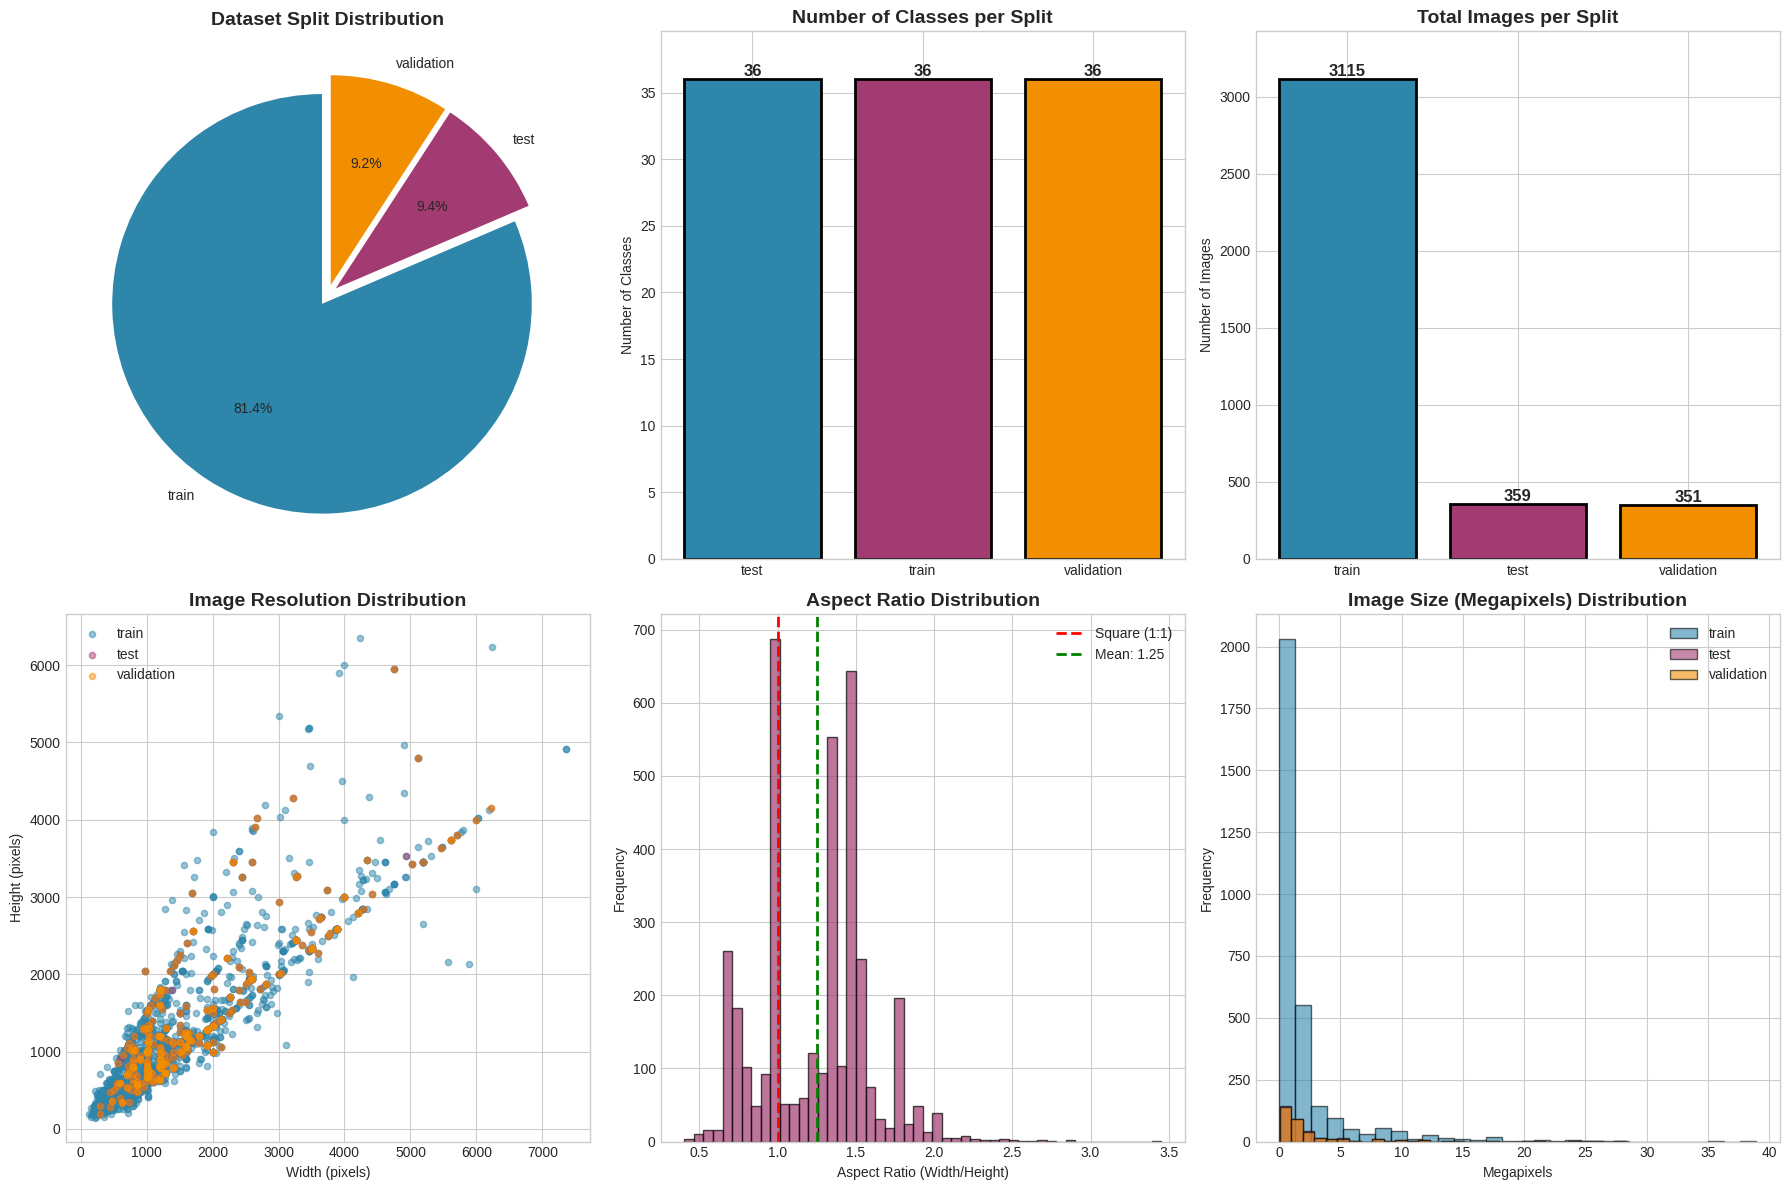

✓ Saved: 01_data_overview.png


In [ ]:
print("\n" + "=" * 60)
print("4. VISUALISASI DATA")
print("=" * 60)

# Create output directory
os.makedirs('/kaggle/working/visualizations', exist_ok=True)

# FIGURE 1: Dataset Split Distribution
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Split counts pie chart
ax1 = axes[0, 0]
split_counts = full_df['split'].value_counts()
colors_split = ['#2E86AB', '#A23B72', '#F18F01']
wedges, texts, autotexts = ax1.pie(split_counts.values, labels=split_counts.index,
                                     autopct='%1.1f%%', colors=colors_split, startangle=90,
                                     explode=(0.05, 0.05, 0.05))
ax1.set_title('Dataset Split Distribution', fontsize=14, fontweight='bold')

# Number of classes per split
ax2 = axes[0, 1]
split_class = full_df.groupby('split')['class'].nunique()
bars = ax2.bar(split_class.index, split_class.values, color=colors_split, edgecolor='black', linewidth=2)
ax2.set_title('Number of Classes per Split', fontsize=14, fontweight='bold')
ax2.set_ylabel('Number of Classes')
ax2.set_ylim(0, max(split_class.values) * 1.1)
for bar in bars:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height)}', ha='center', va='bottom', fontweight='bold', fontsize=12)

# Total images per split (bar chart)
ax3 = axes[0, 2]
bars = ax3.bar(split_counts.index, split_counts.values, color=colors_split, edgecolor='black', linewidth=2)
ax3.set_title('Total Images per Split', fontsize=14, fontweight='bold')
ax3.set_ylabel('Number of Images')
ax3.set_ylim(0, max(split_counts.values) * 1.1)
for bar in bars:
    height = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height)}', ha='center', va='bottom', fontweight='bold', fontsize=12)

# Image resolution distribution (scatter)
ax4 = axes[1, 0]
colors_scatter = {'train': '#2E86AB', 'test': '#A23B72', 'validation': '#F18F01'}
for split, color in colors_scatter.items():
    split_data = full_df[full_df['split'] == split]
    if len(split_data) > 0:
        ax4.scatter(split_data['width'], split_data['height'], alpha=0.5, c=color, label=split, s=20)
ax4.set_xlabel('Width (pixels)')
ax4.set_ylabel('Height (pixels)')
ax4.set_title('Image Resolution Distribution', fontsize=14, fontweight='bold')
ax4.legend()

# Aspect ratio distribution
ax5 = axes[1, 1]
ax5.hist(full_df['aspect_ratio'], bins=50, color='#A23B72', edgecolor='black', alpha=0.7)
ax5.axvline(x=1.0, color='red', linestyle='--', linewidth=2, label='Square (1:1)')
ax5.axvline(x=full_df['aspect_ratio'].mean(), color='green', linestyle='--', linewidth=2,
            label=f'Mean: {full_df["aspect_ratio"].mean():.2f}')
ax5.set_xlabel('Aspect Ratio (Width/Height)')
ax5.set_ylabel('Frequency')
ax5.set_title('Aspect Ratio Distribution', fontsize=14, fontweight='bold')
ax5.legend()

# Megapixels distribution
ax6 = axes[1, 2]
for split, color in colors_scatter.items():
    split_data = full_df[full_df['split'] == split]['megapixels']
    if len(split_data) > 0:
        ax6.hist(split_data, bins=30, alpha=0.6, label=split, color=color, edgecolor='black')
ax6.set_xlabel('Megapixels')
ax6.set_ylabel('Frequency')
ax6.set_title('Image Size (Megapixels) Distribution', fontsize=14, fontweight='bold')
ax6.legend()

plt.tight_layout()
plt.savefig('/kaggle/working/visualizations/01_data_overview.png', dpi=200, bbox_inches='tight')
plt.show()
print("✓ Saved: 01_data_overview.png")

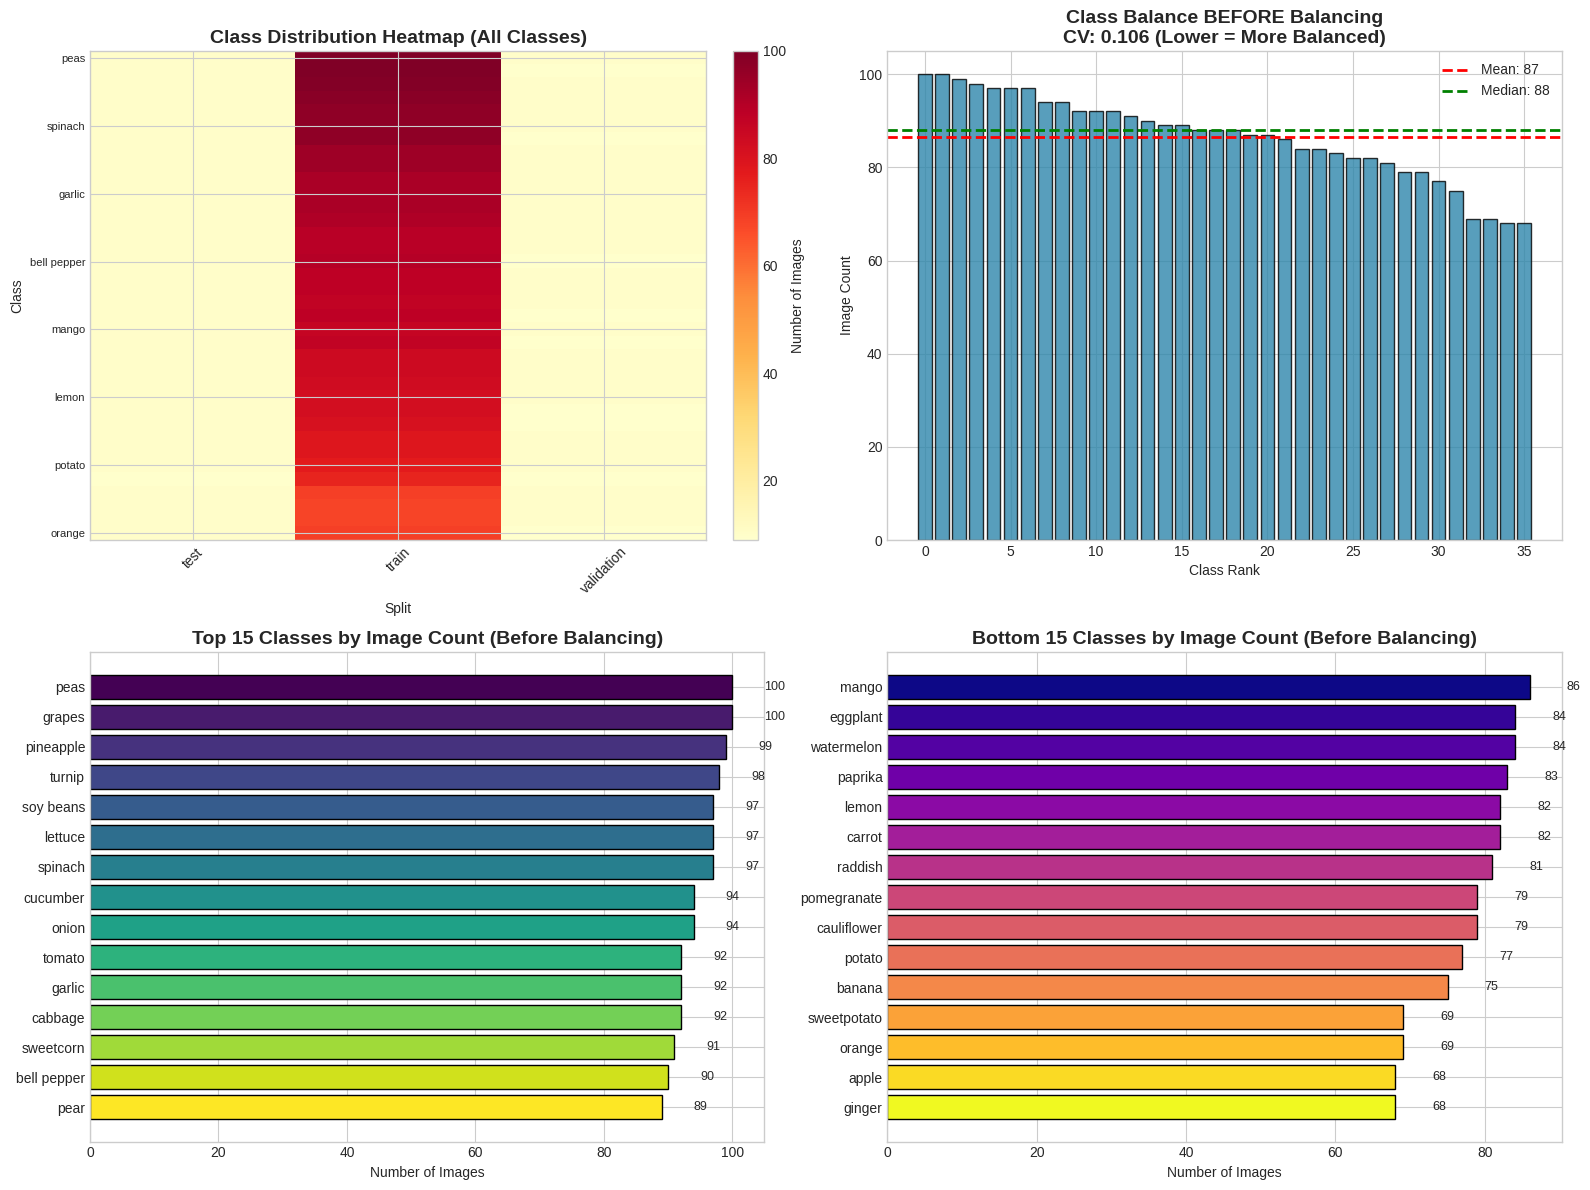

✓ Saved: 02_class_analysis_before.png


In [ ]:
# FIGURE 2: Detailed Class Analysis
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# All classes distribution (heatmap style)
ax1 = axes[0, 0]
class_counts = full_df.groupby(['split', 'class']).size().unstack(fill_value=0)
class_counts = class_counts.T
class_counts_sorted = class_counts.loc[class_counts.sum(axis=1).sort_values(ascending=False).index]

im = ax1.imshow(class_counts_sorted.values, aspect='auto', cmap='YlOrRd')
ax1.set_xticks(range(len(class_counts_sorted.columns)))
ax1.set_xticklabels(class_counts_sorted.columns, rotation=45)
ax1.set_yticks(range(0, len(class_counts_sorted), 5))
ax1.set_yticklabels(class_counts_sorted.index[::5], fontsize=8)
ax1.set_xlabel('Split')
ax1.set_ylabel('Class')
ax1.set_title('Class Distribution Heatmap (All Classes)', fontsize=14, fontweight='bold')
plt.colorbar(im, ax=ax1, fraction=0.046, pad=0.04, label='Number of Images')

# Class balance analysis (BEFORE)
ax2 = axes[0, 1]
train_counts_before = train_df['class'].value_counts().sort_values(ascending=False)
cv_before = train_counts_before.std() / train_counts_before.mean()
x_pos = range(len(train_counts_before))
bars = ax2.bar(x_pos, train_counts_before.values, color='#2E86AB', edgecolor='black', alpha=0.8)
ax2.set_xlabel('Class Rank')
ax2.set_ylabel('Image Count')
ax2.set_title(f'Class Balance BEFORE Balancing\nCV: {cv_before:.3f} (Lower = More Balanced)',
              fontsize=14, fontweight='bold')
ax2.axhline(y=train_counts_before.mean(), color='red', linestyle='--', linewidth=2,
            label=f'Mean: {train_counts_before.mean():.0f}')
ax2.axhline(y=train_counts_before.median(), color='green', linestyle='--', linewidth=2,
            label=f'Median: {train_counts_before.median():.0f}')
ax2.legend()

# Top 15 classes by image count (train)
ax3 = axes[1, 0]
top_15 = train_counts_before.head(15)
colors_bar = plt.cm.viridis(np.linspace(0, 1, 15))
bars = ax3.barh(range(len(top_15)), top_15.values, color=colors_bar, edgecolor='black')
ax3.set_yticks(range(len(top_15)))
ax3.set_yticklabels(top_15.index, fontsize=10)
ax3.set_xlabel('Number of Images')
ax3.set_title('Top 15 Classes by Image Count (Before Balancing)', fontsize=14, fontweight='bold')
ax3.invert_yaxis()
for bar in bars:
    width = bar.get_width()
    ax3.text(width + 5, bar.get_y() + bar.get_height()/2.,
             f'{int(width)}', ha='left', va='center', fontsize=9)

# Bottom 15 classes by image count (train)
ax4 = axes[1, 1]
bottom_15 = train_counts_before.tail(15)
colors_bar = plt.cm.plasma(np.linspace(0, 1, 15))
bars = ax4.barh(range(len(bottom_15)), bottom_15.values, color=colors_bar, edgecolor='black')
ax4.set_yticks(range(len(bottom_15)))
ax4.set_yticklabels(bottom_15.index, fontsize=10)
ax4.set_xlabel('Number of Images')
ax4.set_title('Bottom 15 Classes by Image Count (Before Balancing)', fontsize=14, fontweight='bold')
ax4.invert_yaxis()
for bar in bars:
    width = bar.get_width()
    ax4.text(width + 5, bar.get_y() + bar.get_height()/2.,
             f'{int(width)}', ha='left', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('/kaggle/working/visualizations/02_class_analysis_before.png', dpi=200, bbox_inches='tight')
plt.show()
print("✓ Saved: 02_class_analysis_before.png")

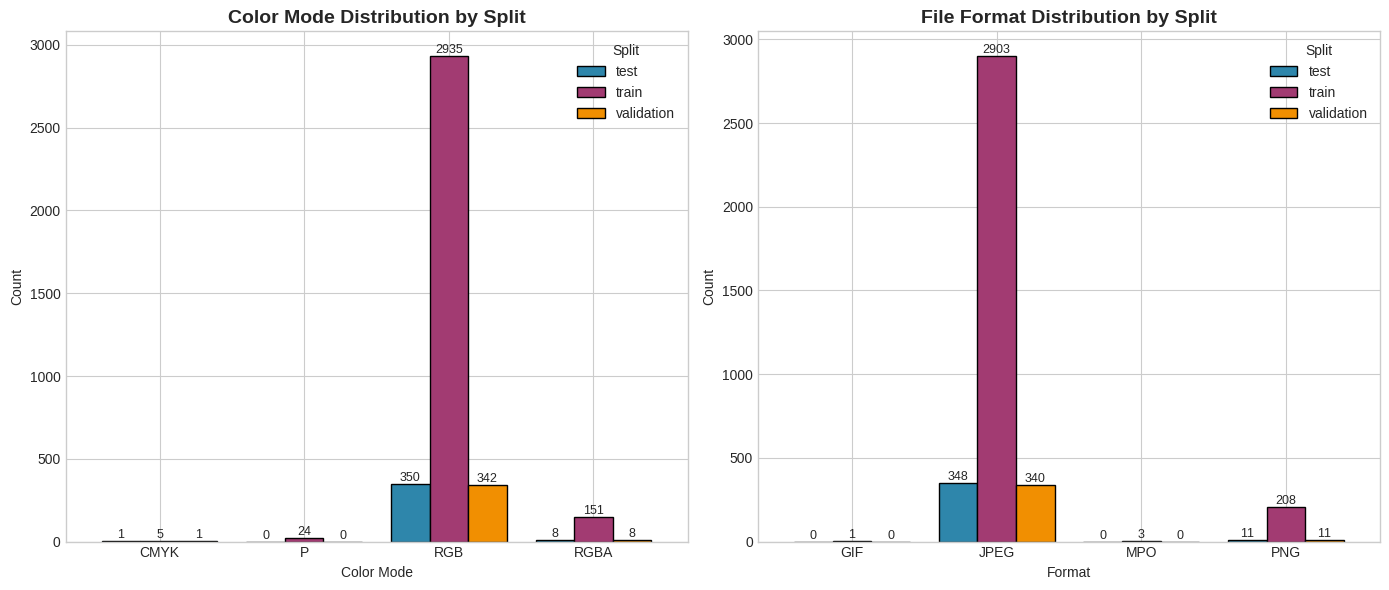

✓ Saved: 03_format_distribution.png


In [ ]:
# FIGURE 3: Color Mode and Format Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Color mode by split
ax1 = axes[0]
color_mode_split = pd.crosstab(full_df['channels'], full_df['split'])
color_mode_split.plot(kind='bar', ax=ax1, color=colors_split, edgecolor='black', width=0.8)
ax1.set_title('Color Mode Distribution by Split', fontsize=14, fontweight='bold')
ax1.set_xlabel('Color Mode')
ax1.set_ylabel('Count')
ax1.legend(title='Split')
ax1.tick_params(axis='x', rotation=0)
for container in ax1.containers:
    ax1.bar_label(container, fmt='%d', fontsize=9)

# File format by split
ax2 = axes[1]
format_split = pd.crosstab(full_df['format'], full_df['split'])
format_split.plot(kind='bar', ax=ax2, color=colors_split, edgecolor='black', width=0.8)
ax2.set_title('File Format Distribution by Split', fontsize=14, fontweight='bold')
ax2.set_xlabel('Format')
ax2.set_ylabel('Count')
ax2.legend(title='Split')
ax2.tick_params(axis='x', rotation=0)
for container in ax2.containers:
    ax2.bar_label(container, fmt='%d', fontsize=9)

plt.tight_layout()
plt.savefig('/kaggle/working/visualizations/03_format_distribution.png', dpi=200, bbox_inches='tight')
plt.show()
print("✓ Saved: 03_format_distribution.png")

## 5. Sample Images Visualization


5. SAMPLE IMAGES VISUALIZATION


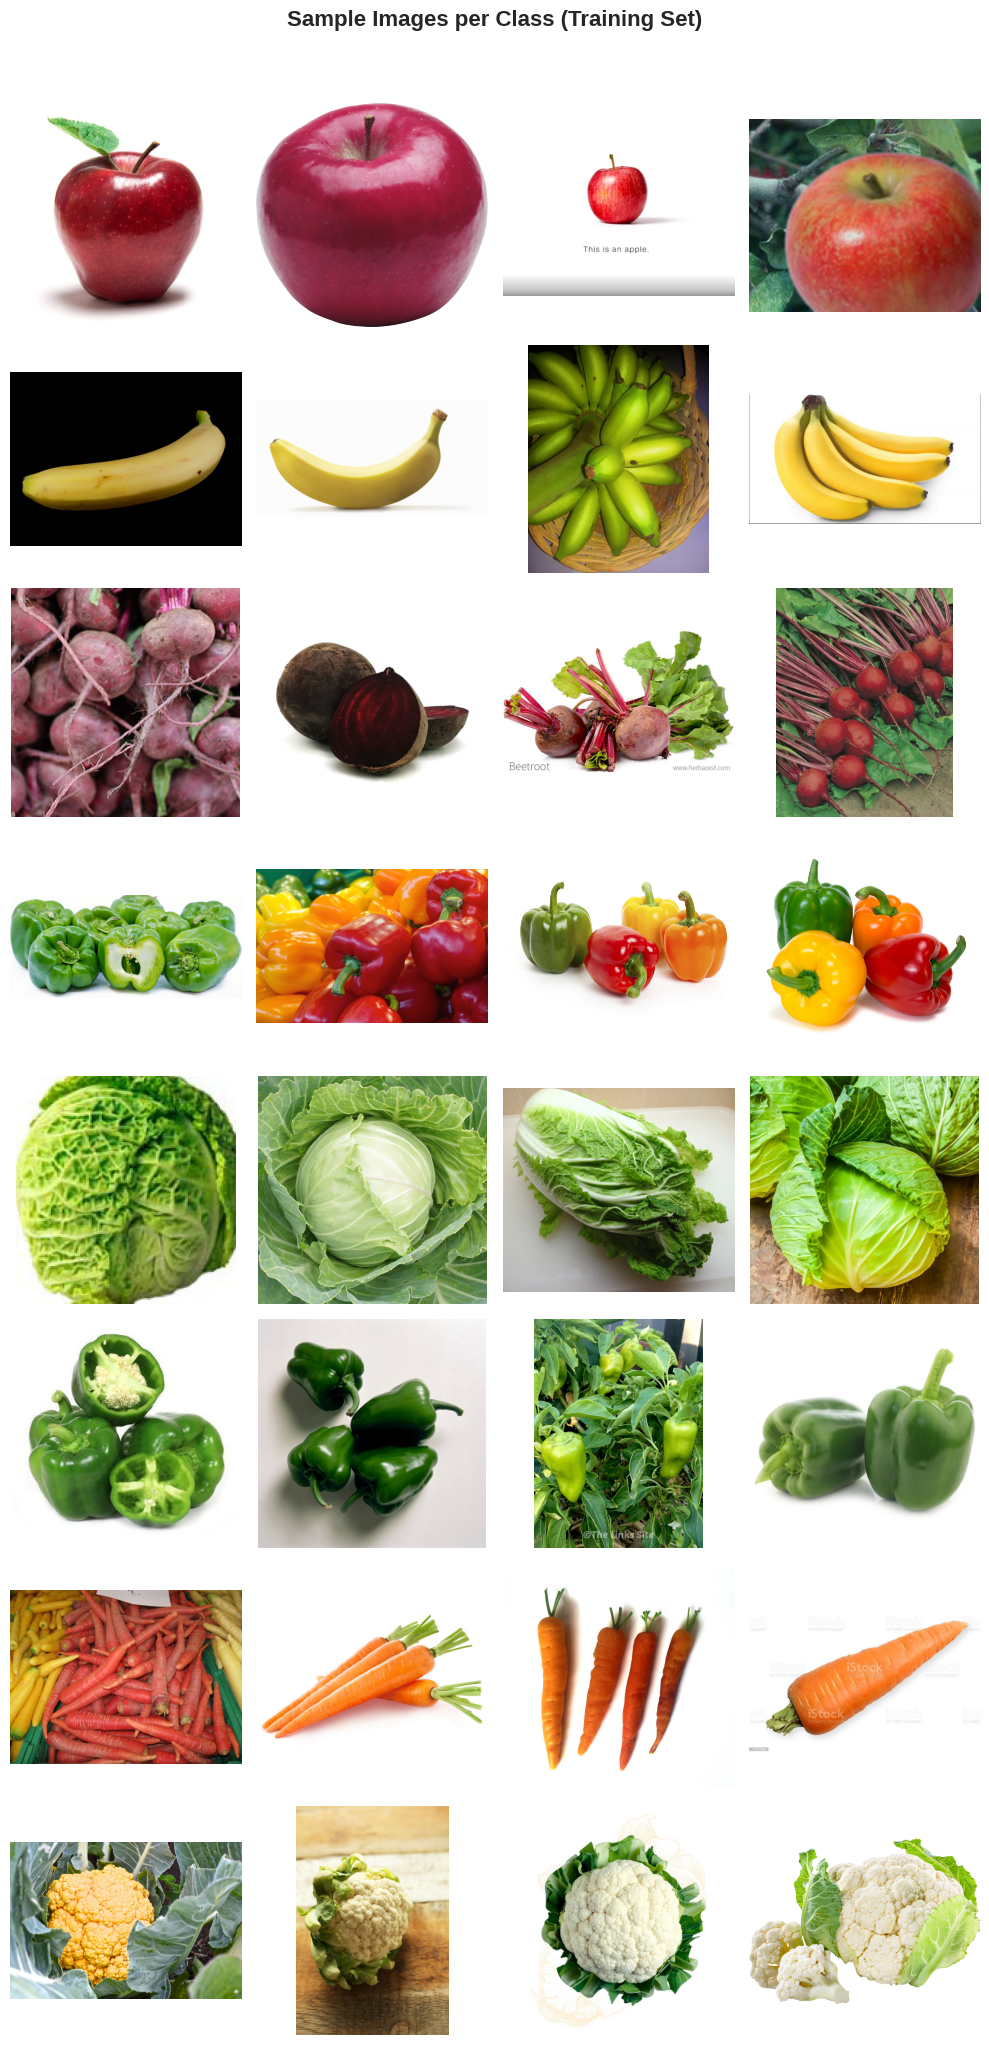

✓ Saved: 04_sample_images.png


In [ ]:
print("\n" + "=" * 60)
print("5. SAMPLE IMAGES VISUALIZATION")
print("=" * 60)

def plot_class_samples(df, num_classes=8, samples_per_class=4):
    """Plot sample images from each class"""
    classes = df['class'].unique()[:num_classes]
    fig, axes = plt.subplots(num_classes, samples_per_class, figsize=(samples_per_class*2.5, num_classes*2.5))

    if num_classes == 1:
        axes = axes.reshape(1, -1)

    for i, class_name in enumerate(classes):
        class_images = df[df['class'] == class_name]['path'].values[:samples_per_class]

        for j, img_path in enumerate(class_images):
            try:
                img = Image.open(img_path)
                axes[i, j].imshow(img)
                axes[i, j].axis('off')
                if j == 0:
                    axes[i, j].set_ylabel(class_name, fontsize=11, fontweight='bold', rotation=0,
                                         labelpad=40, va='center')
            except Exception as e:
                axes[i, j].axis('off')

    plt.suptitle('Sample Images per Class (Training Set)', fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    return fig

fig = plot_class_samples(train_df, num_classes=min(8, len(train_df['class'].unique())), samples_per_class=4)
plt.savefig('/kaggle/working/visualizations/04_sample_images.png', dpi=200, bbox_inches='tight')
plt.show()
print("✓ Saved: 04_sample_images.png")

## 6. Data Preprocessing Pipeline


6. DATA PREPROCESSING PIPELINE
Target Image Size: (224, 224)
Normalization: imagenet

Demonstrating preprocessing pipeline...


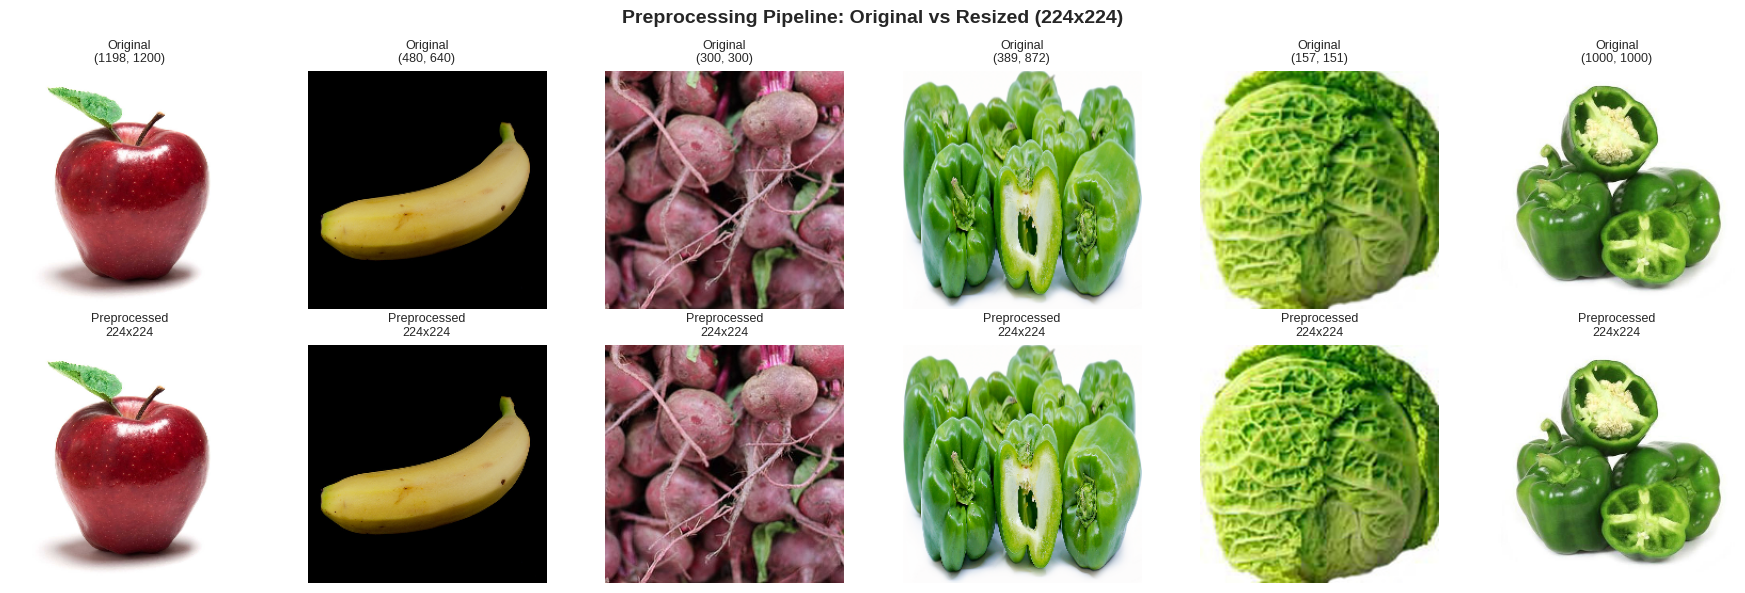

✓ Saved: 05_preprocessing_demo.png


In [ ]:
print("\n" + "=" * 60)
print("6. DATA PREPROCESSING PIPELINE")
print("=" * 60)

# Preprocessing parameters
IMG_SIZE = (224, 224)
NORMALIZATION = 'imagenet'

print(f"Target Image Size: {IMG_SIZE}")
print(f"Normalization: {NORMALIZATION}")

def preprocess_image(image_path, target_size=IMG_SIZE, normalize=True):
    img = cv2.imread(image_path)
    if img is None:
        return None
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img, target_size, interpolation=cv2.INTER_LANCZOS4)
    if normalize:
        if NORMALIZATION == 'imagenet':
            mean = np.array([0.485, 0.456, 0.406])
            std = np.array([0.229, 0.224, 0.225])
            img_normalized = (img_resized / 255.0 - mean) / std
        else:
            img_normalized = img_resized / 255.0
    else:
        img_normalized = img_resized
    return img_normalized

print("\nDemonstrating preprocessing pipeline...")
sample_paths = train_df.groupby('class').first()['path'].values[:6]

fig, axes = plt.subplots(2, 6, figsize=(18, 6))

for i, img_path in enumerate(sample_paths):
    img_original = cv2.imread(img_path)
    img_original = cv2.cvtColor(img_original, cv2.COLOR_BGR2RGB)
    img_processed = preprocess_image(img_path, normalize=False)

    axes[0, i].imshow(cv2.resize(img_original, IMG_SIZE))
    axes[0, i].axis('off')
    axes[0, i].set_title(f'Original\n{img_original.shape[:2]}', fontsize=9)

    axes[1, i].imshow(img_processed)
    axes[1, i].axis('off')
    axes[1, i].set_title(f'Preprocessed\n{IMG_SIZE[0]}x{IMG_SIZE[1]}', fontsize=9)

plt.suptitle('Preprocessing Pipeline: Original vs Resized (224x224)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/visualizations/05_preprocessing_demo.png', dpi=200, bbox_inches='tight')
plt.show()
print("✓ Saved: 05_preprocessing_demo.png")

## 7. Data Augmentasi untuk Balancing Kelas

In [ ]:
print("\n" + "=" * 60)
print("7. DATA AUGMENTASI UNTUK BALANCING KELAS")
print("=" * 60)

# Parameter balancing
TARGET_IMAGES_PER_CLASS = 500  # Target jumlah gambar per kelas (bisa diubah ke 800)

print(f"\n🎯 TARGET BALANCING:")
print(f"   Target images per class: {TARGET_IMAGES_PER_CLASS}")
print(f"   Total classes: {NUM_CLASSES}")
print(f"   Target total training images: {TARGET_IMAGES_PER_CLASS * NUM_CLASSES:,}")

# Hitung kebutuhan augmentasi per kelas
train_counts_series = train_df['class'].value_counts()
original_total_training_images = sum(train_counts_series.get(c, 0) for c in class_names) # Capture original total here
augmentation_needed = {}

print("\n📊 AUGMENTATION NEEDS PER CLASS:")
print("-" * 50)
print(f"{'Class':<20} {'Original':<10} {'Needed':<10} {'Multiply':<10}")
print("-" * 50)

for class_name in class_names:
    original_count = train_counts_series.get(class_name, 0)
    if original_count < TARGET_IMAGES_PER_CLASS:
        needed = TARGET_IMAGES_PER_CLASS - original_count
        multiplier = np.ceil(TARGET_IMAGES_PER_CLASS / original_count)
        augmentation_needed[class_name] = {
            'original': original_count,
            'needed': needed,
            'multiplier': multiplier,
            'target': TARGET_IMAGES_PER_CLASS
        }
        print(f"{class_name:<20} {original_count:<10} {needed:<10} {multiplier:<10.1f}x")
    else:
        augmentation_needed[class_name] = {
            'original': original_count,
            'needed': 0,
            'multiplier': 1,
            'target': original_count  # Keep as is
        }
        print(f"{class_name:<20} {original_count:<10} {'0':<10} {'1.0x':<10} (already enough)")

# Setup augmentation parameters
augmentation_params = {
    'rotation_range': 40,
    'width_shift_range': 0.2,
    'height_shift_range': 0.2,
    'shear_range': 0.2,
    'zoom_range': 0.2,
    'horizontal_flip': True,
    'vertical_flip': True,
    'brightness_range': [0.7, 1.3],
    'fill_mode': 'nearest'
}

print("\n🔧 AUGMENTATION PARAMETERS:")
for key, value in augmentation_params.items():
    print(f"   {key:20s}: {value}")

# Try to import tensorflow
try:
    import tensorflow as tf
    from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array, array_to_img
    TF_AVAILABLE = True
    print("\n✓ Using TensorFlow for augmentation")
except ImportError:
    TF_AVAILABLE = False
    print("\n⚠ TensorFlow not available, using OpenCV for basic augmentation")

# Function to augment a single image multiple times (OpenCV based, not used if TF_AVAILABLE)
def augment_image_opencv(img, params):
    """Apply augmentations using OpenCV"""
    h, w = img.shape[:2]

    # Random rotation
    if np.random.random() < 0.5:
        angle = np.random.uniform(-params['rotation_range'], params['rotation_range'])
        M = cv2.getRotationMatrix2D((w/2, h/2), angle, 1)
        img = cv2.warpAffine(img, M, (w, h))

    # Random horizontal flip
    if params['horizontal_flip'] and np.random.random() < 0.5:
        img = cv2.flip(img, 1)

    # Random vertical flip
    if params['vertical_flip'] and np.random.random() < 0.5:
        img = cv2.flip(img, 0)

    # Random brightness adjustment
    brightness = np.random.uniform(params['brightness_range'][0], params['brightness_range'][1])
    img = np.clip(img * brightness, 0, 255).astype(np.uint8)

    return img

# --- New code to generate and save augmented images ---
AUGMENTED_TRAIN_DIR = '/kaggle/working/augmented_train_data'
os.makedirs(AUGMENTED_TRAIN_DIR, exist_ok=True)

# List to store info for the new train_df
new_train_data_records = []

print("\n🚀 GENERATING AND SAVING AUGMENTED IMAGES...")

if TF_AVAILABLE:
    # Initialize ImageDataGenerator for applying transformations
    datagen_transformer = ImageDataGenerator(
        rotation_range=augmentation_params['rotation_range'],
        width_shift_range=augmentation_params['width_shift_range'],
        height_shift_range=augmentation_params['height_shift_range'],
        shear_range=augmentation_params['shear_range'],
        zoom_range=augmentation_params['zoom_range'],
        horizontal_flip=augmentation_params['horizontal_flip'],
        vertical_flip=augmentation_params['vertical_flip'],
        brightness_range=augmentation_params['brightness_range'],
        fill_mode=augmentation_params['fill_mode']
    )

    for class_name in class_names:
        class_original_df = train_df[train_df['class'] == class_name]
        original_images_paths = class_original_df['path'].tolist()

        class_output_dir = os.path.join(AUGMENTED_TRAIN_DIR, class_name)
        os.makedirs(class_output_dir, exist_ok=True)

        current_class_images_count = 0

        # First, add all original images to the new dataset list and save them to the augmented dir
        for original_img_path in original_images_paths:
            try:
                img = load_img(original_img_path, target_size=IMG_SIZE)
                new_filename = os.path.basename(original_img_path)
                img.save(os.path.join(class_output_dir, new_filename))

                new_train_data_records.append({
                    'split': 'train',
                    'class': class_name,
                    'filename': new_filename,
                    'path': os.path.join(class_output_dir, new_filename)
                })
                current_class_images_count += 1
            except Exception as e:
                print(f"Error copying original image {original_img_path} for {class_name}: {e}")

        # Now, generate augmented images if needed
        needed_augmentations = augmentation_needed[class_name]['target'] - current_class_images_count

        if needed_augmentations > 0:
            print(f"  - Augmenting class '{class_name}': from {current_class_images_count} to {augmentation_needed[class_name]['target']} images (need {needed_augmentations} new)")
            aug_idx = 0
            while aug_idx < needed_augmentations:
                try:
                    # Randomly pick an original image to augment
                    source_img_path = np.random.choice(original_images_paths)
                    img = load_img(source_img_path, target_size=IMG_SIZE)
                    img_array = img_to_array(img)
                    img_array = img_array.reshape((1,) + img_array.shape) # Add batch dimension

                    # Apply random transformation
                    transformed_img_array = datagen_transformer.random_transform(img_array[0])
                    transformed_img = array_to_img(transformed_img_array) # Convert back to PIL Image

                    new_filename = f'aug_{class_name}_{current_class_images_count + aug_idx:04d}.jpeg'
                    save_path = os.path.join(class_output_dir, new_filename)
                    transformed_img.save(save_path)

                    new_train_data_records.append({
                        'split': 'train',
                        'class': class_name,
                        'filename': new_filename,
                        'path': save_path
                    })
                    aug_idx += 1
                except Exception as e:
                    print(f"Error generating augmented image for {class_name}: {e}")
                    break # Stop if an error occurs
        else:
            print(f"  - Class '{class_name}' already has {current_class_images_count} images (target {augmentation_needed[class_name]['target']}). No augmentation needed.")

    # Reconstruct train_df from the collected data
    train_df = pd.DataFrame(new_train_data_records)
    print(f"\nTotal training images AFTER saving augmentation: {len(train_df):,}")
    print(f"Augmented training data saved to: {AUGMENTED_TRAIN_DIR}")

else:
    print("\nSkipping image saving as TensorFlow is not available for ImageDataGenerator.")
    print("If you want to save augmented images, please ensure TensorFlow is installed.")

# Calculate final dataset size after balancing (based on newly constructed train_df)
total_before = original_total_training_images # Use the captured original total
total_after = len(train_df) # This now refers to the total images after saving all augmentations

# Recalculate cv_after based on the new train_df
train_counts_after_save = train_df['class'].value_counts()
after_counts_adj = [train_counts_after_save.get(c, 0) for c in class_names]
cv_after = np.std(after_counts_adj) / np.mean(after_counts_adj) if np.mean(after_counts_adj) > 0 else 0

print("\n📈 DATASET SIZE IMPACT (BALANCING):")
print("-" * 50)
print(f"   Total training images BEFORE (original train_df): {total_before:,}")
print(f"   Total training images AFTER (saved augmented train_df): {total_after:,}")
# Fix the f-string syntax and the calculation
increase_percentage = ((total_after / total_before) - 1) * 100 if total_before > 0 else 0
print(f"   Increase: {total_after - total_before:,} images ({increase_percentage:.1f}%) -- This calculation needs review for before/after comparison")
print(f"   Images per class AFTER: {TARGET_IMAGES_PER_CLASS} (target)")
print(f"   CV AFTER saving augmented images: {cv_after:.4f}")


7. DATA AUGMENTASI UNTUK BALANCING KELAS

🎯 TARGET BALANCING:
   Target images per class: 500
   Total classes: 36
   Target total training images: 18,000

📊 AUGMENTATION NEEDS PER CLASS:
--------------------------------------------------
Class                Original   Needed     Multiply  
--------------------------------------------------
apple                68         432        8.0       x
banana               75         425        7.0       x
beetroot             88         412        6.0       x
bell pepper          90         410        6.0       x
cabbage              92         408        6.0       x
capsicum             89         411        6.0       x
carrot               82         418        7.0       x
cauliflower          79         421        7.0       x
chilli pepper        87         413        6.0       x
corn                 87         413        6.0       x
cucumber             94         406        6.0       x
eggplant             84         416        6.0    

## 8. Visualization: Before vs After Balancing


8. VISUALIZATION: BEFORE vs AFTER BALANCING


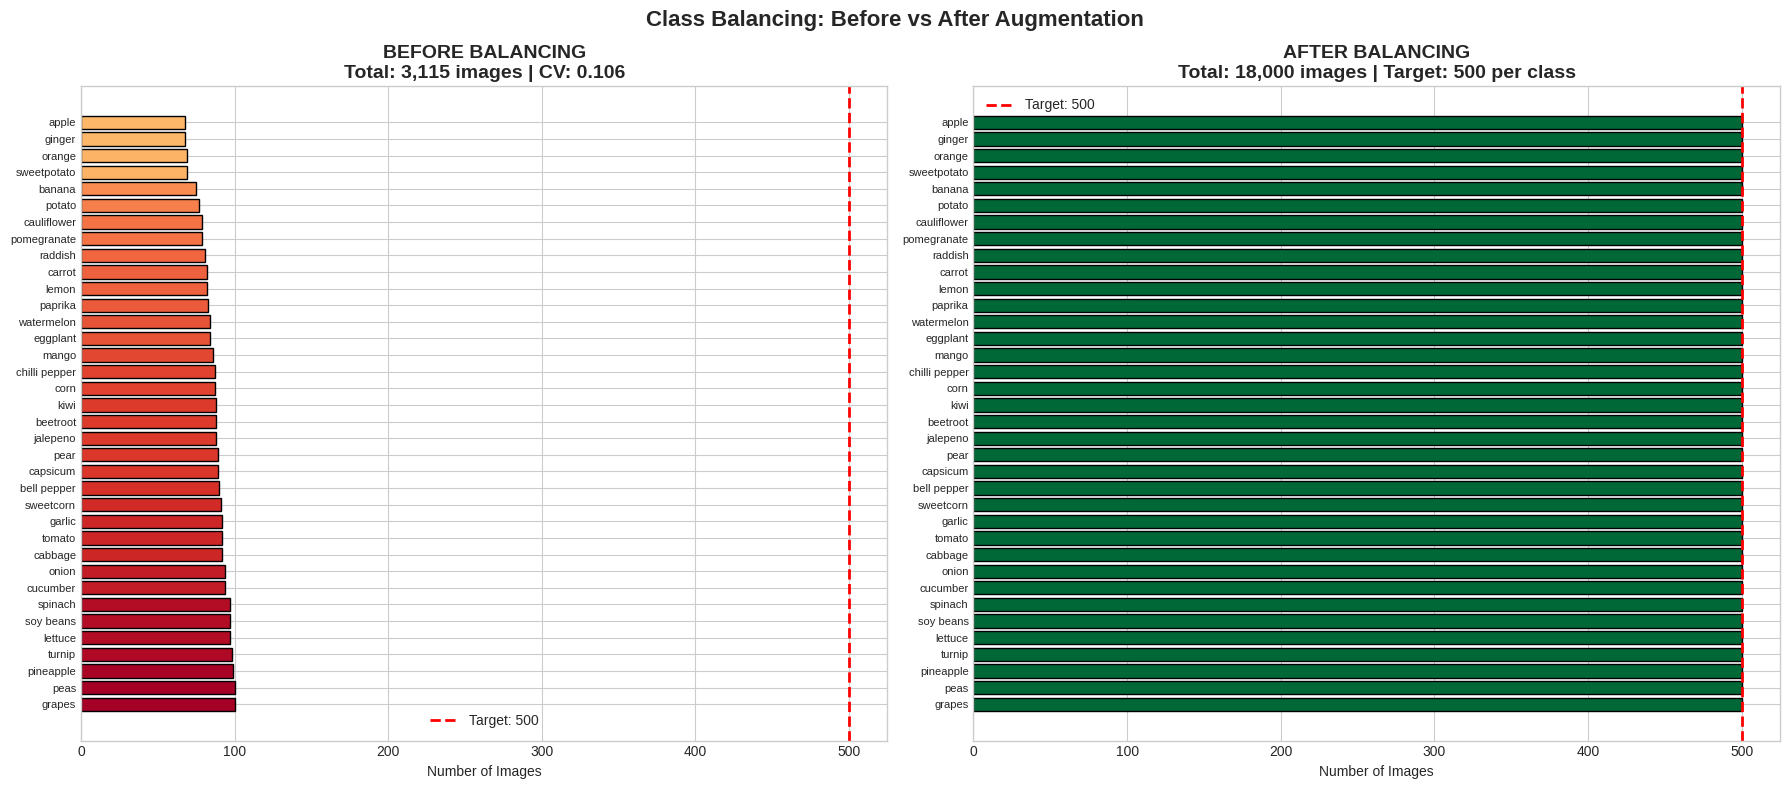

✓ Saved: 06_balancing_comparison.png


In [ ]:
print("\n" + "=" * 60)
print("8. VISUALIZATION: BEFORE vs AFTER BALANCING")
print("=" * 60)

# Create data for visualization
classes_list = class_names
before_counts_list = [train_counts_series.get(c, 0) for c in classes_list]
after_counts_list = [augmentation_needed[c]['target'] for c in classes_list]

# Sort by before count for better visualization
sorted_indices = np.argsort(before_counts_list)
classes_sorted = [classes_list[i] for i in sorted_indices]
before_sorted = [before_counts_list[i] for i in sorted_indices]
after_sorted = [after_counts_list[i] for i in sorted_indices]

# FIGURE: Before vs After Balancing - Bar Chart
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Before balancing
ax1 = axes[0]
colors_before = plt.cm.RdYlGn_r(np.array(before_sorted) / max(before_sorted))
bars1 = ax1.barh(range(len(classes_sorted)), before_sorted, color=colors_before, edgecolor='black')
ax1.set_yticks(range(len(classes_sorted)))
ax1.set_yticklabels(classes_sorted, fontsize=8)
ax1.set_xlabel('Number of Images')
ax1.set_title(f'BEFORE BALANCING\nTotal: {total_before:,} images | CV: {cv_before:.3f}',
              fontsize=14, fontweight='bold')
ax1.axvline(x=TARGET_IMAGES_PER_CLASS, color='red', linestyle='--', linewidth=2,
            label=f'Target: {TARGET_IMAGES_PER_CLASS}')
ax1.legend()
ax1.invert_yaxis()

# After balancing
ax2 = axes[1]
colors_after = plt.cm.RdYlGn(np.array(after_sorted) / max(after_sorted))
bars2 = ax2.barh(range(len(classes_sorted)), after_sorted, color=colors_after, edgecolor='black')
ax2.set_yticks(range(len(classes_sorted)))
ax2.set_yticklabels(classes_sorted, fontsize=8)
ax2.set_xlabel('Number of Images')
ax2.set_title(f'AFTER BALANCING\nTotal: {total_after:,} images | Target: {TARGET_IMAGES_PER_CLASS} per class',
              fontsize=14, fontweight='bold')
ax2.axvline(x=TARGET_IMAGES_PER_CLASS, color='red', linestyle='--', linewidth=2,
            label=f'Target: {TARGET_IMAGES_PER_CLASS}')
ax2.legend()
ax2.invert_yaxis()

plt.suptitle('Class Balancing: Before vs After Augmentation', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/visualizations/06_balancing_comparison.png', dpi=200, bbox_inches='tight')
plt.show()
print("✓ Saved: 06_balancing_comparison.png")

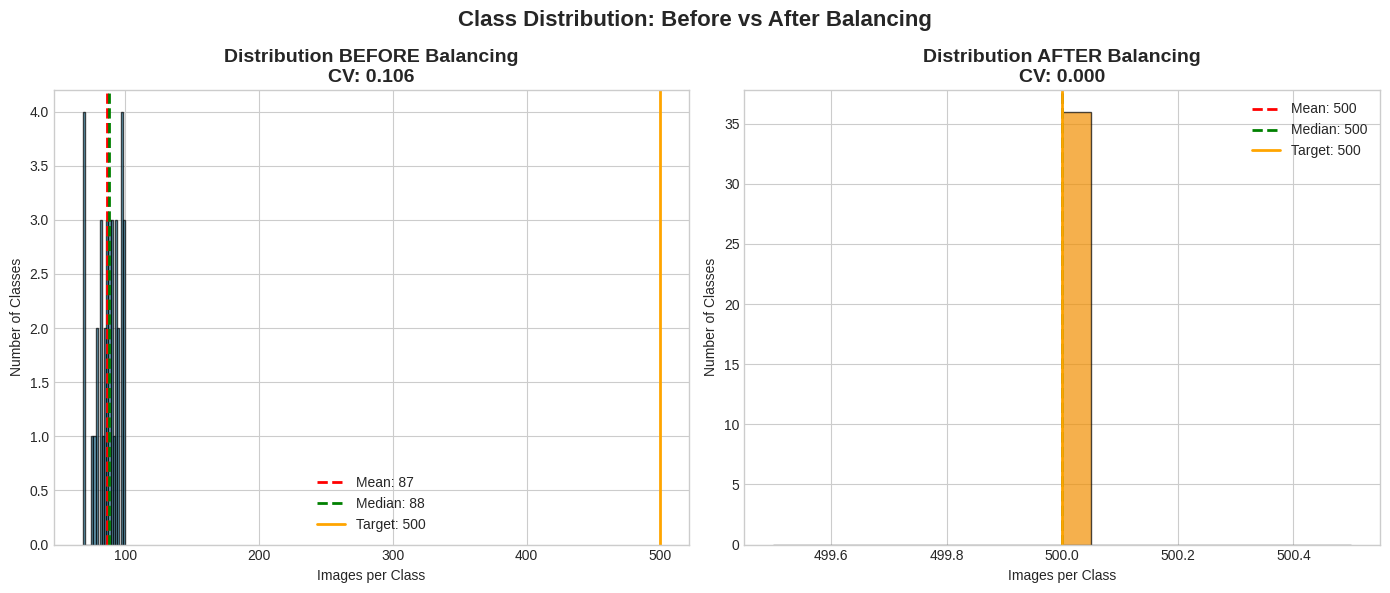

✓ Saved: 07_distribution_comparison.png


In [ ]:
# FIGURE: Distribution comparison (histogram)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Before balancing histogram
ax1 = axes[0]
ax1.hist(before_counts_list, bins=20, color='#2E86AB', edgecolor='black', alpha=0.7)
ax1.axvline(x=np.mean(before_counts_list), color='red', linestyle='--', linewidth=2,
            label=f'Mean: {np.mean(before_counts_list):.0f}')
ax1.axvline(x=np.median(before_counts_list), color='green', linestyle='--', linewidth=2,
            label=f'Median: {np.median(before_counts_list):.0f}')
ax1.axvline(x=TARGET_IMAGES_PER_CLASS, color='orange', linestyle='-', linewidth=2,
            label=f'Target: {TARGET_IMAGES_PER_CLASS}')
ax1.set_xlabel('Images per Class')
ax1.set_ylabel('Number of Classes')
ax1.set_title(f'Distribution BEFORE Balancing\nCV: {cv_before:.3f}', fontsize=14, fontweight='bold')
ax1.legend()

# After balancing histogram
ax2 = axes[1]
# After balancing - some classes may have more than target if original already exceeded
after_counts_adj = [max(TARGET_IMAGES_PER_CLASS, c) for c in before_counts_list]
cv_after = np.std(after_counts_adj) / np.mean(after_counts_adj) if np.mean(after_counts_adj) > 0 else 0
ax2.hist(after_counts_adj, bins=20, color='#F18F01', edgecolor='black', alpha=0.7)
ax2.axvline(x=np.mean(after_counts_adj), color='red', linestyle='--', linewidth=2,
            label=f'Mean: {np.mean(after_counts_adj):.0f}')
ax2.axvline(x=np.median(after_counts_adj), color='green', linestyle='--', linewidth=2,
            label=f'Median: {np.median(after_counts_adj):.0f}')
ax2.axvline(x=TARGET_IMAGES_PER_CLASS, color='orange', linestyle='-', linewidth=2,
            label=f'Target: {TARGET_IMAGES_PER_CLASS}')
ax2.set_xlabel('Images per Class')
ax2.set_ylabel('Number of Classes')
ax2.set_title(f'Distribution AFTER Balancing\nCV: {cv_after:.3f}', fontsize=14, fontweight='bold')
ax2.legend()

plt.suptitle('Class Distribution: Before vs After Balancing', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/visualizations/07_distribution_comparison.png', dpi=200, bbox_inches='tight')
plt.show()
print("✓ Saved: 07_distribution_comparison.png")

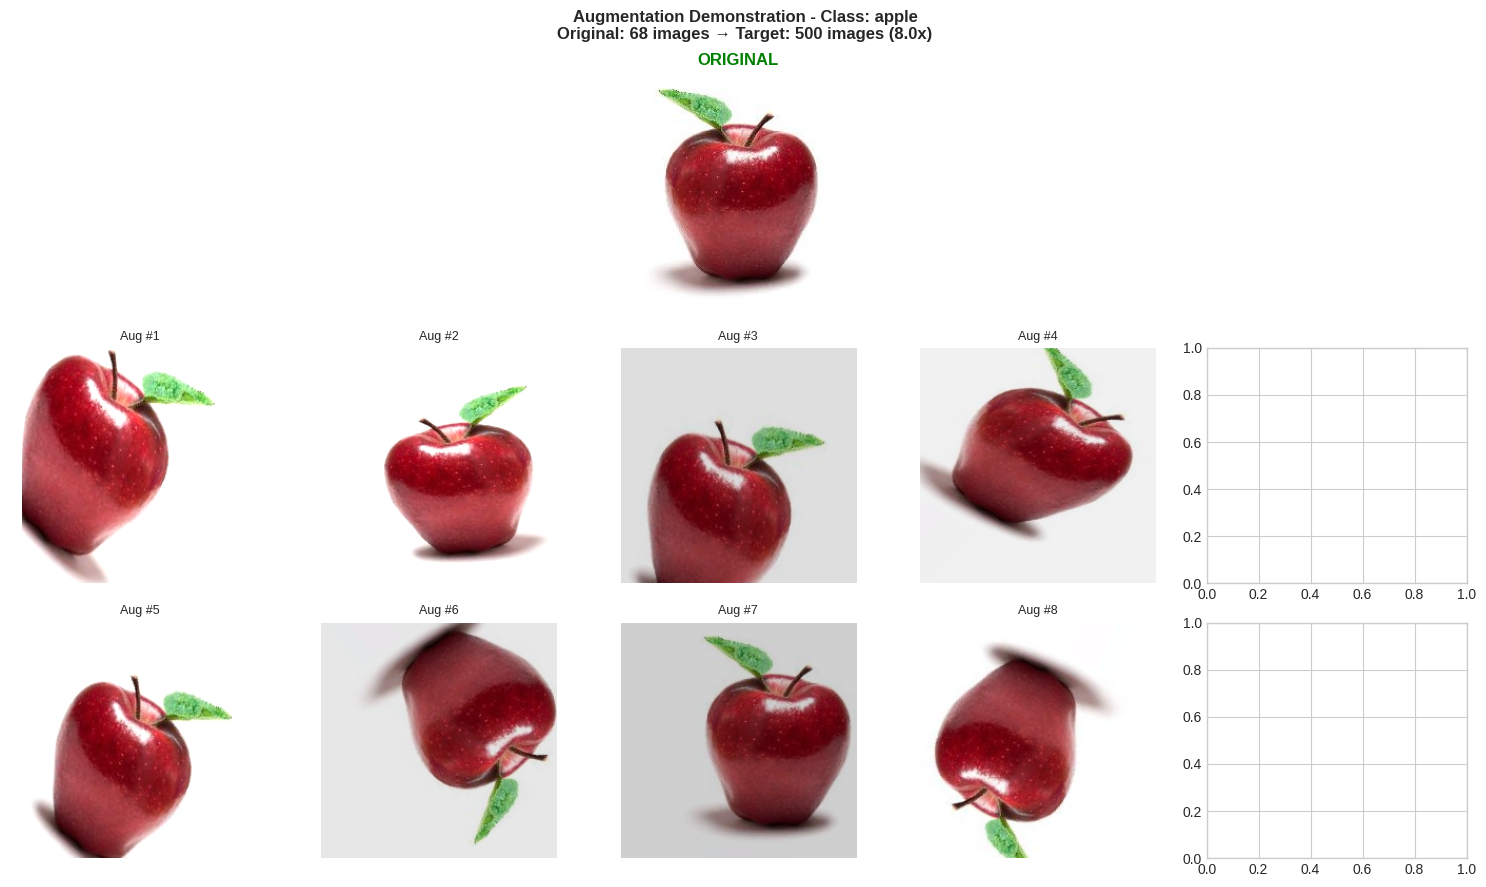

✓ Saved: 08_augmentation_demo.png


In [ ]:
# FIGURE: Augmentation demonstration for a class with few samples
if TF_AVAILABLE:
    # Find a class with few samples for demonstration
    few_class = min(augmentation_needed.items(), key=lambda x: x[1]['original'] if x[1]['original'] > 0 else float('inf'))[0]
    few_class_path = train_df[train_df['class'] == few_class].iloc[0]['path']
    original_count = augmentation_needed[few_class]['original']
    multiplier = augmentation_needed[few_class]['multiplier']

    fig, axes = plt.subplots(3, 5, figsize=(15, 9))
    fig.suptitle(f'Augmentation Demonstration - Class: {few_class}\nOriginal: {original_count} images → Target: {TARGET_IMAGES_PER_CLASS} images ({multiplier:.1f}x)',
                 fontsize=12, fontweight='bold')

    datagen = ImageDataGenerator(**augmentation_params)
    img = load_img(few_class_path, target_size=IMG_SIZE)
    img_array = img_to_array(img)
    img_array = img_array.reshape((1,) + img_array.shape)

    # Original
    axes[0, 2].imshow(img_array[0].astype('uint8'))
    axes[0, 2].set_title('ORIGINAL', fontsize=12, fontweight='bold', color='green')
    axes[0, 2].axis('off')

    for j in range(5):
        if j != 2:
            axes[0, j].axis('off')

    # Augmented versions
    aug_iter = datagen.flow(img_array, batch_size=1)
    for i in range(8):
        aug_img = next(aug_iter)[0].astype('uint8')
        row = 1 + (i // 4)
        col = i % 4
        axes[row, col].imshow(aug_img)
        axes[row, col].set_title(f'Aug #{i+1}', fontsize=9)
        axes[row, col].axis('off')

    plt.tight_layout()
    plt.savefig('/kaggle/working/visualizations/08_augmentation_demo.png', dpi=200, bbox_inches='tight')
    plt.show()
    print("✓ Saved: 08_augmentation_demo.png")

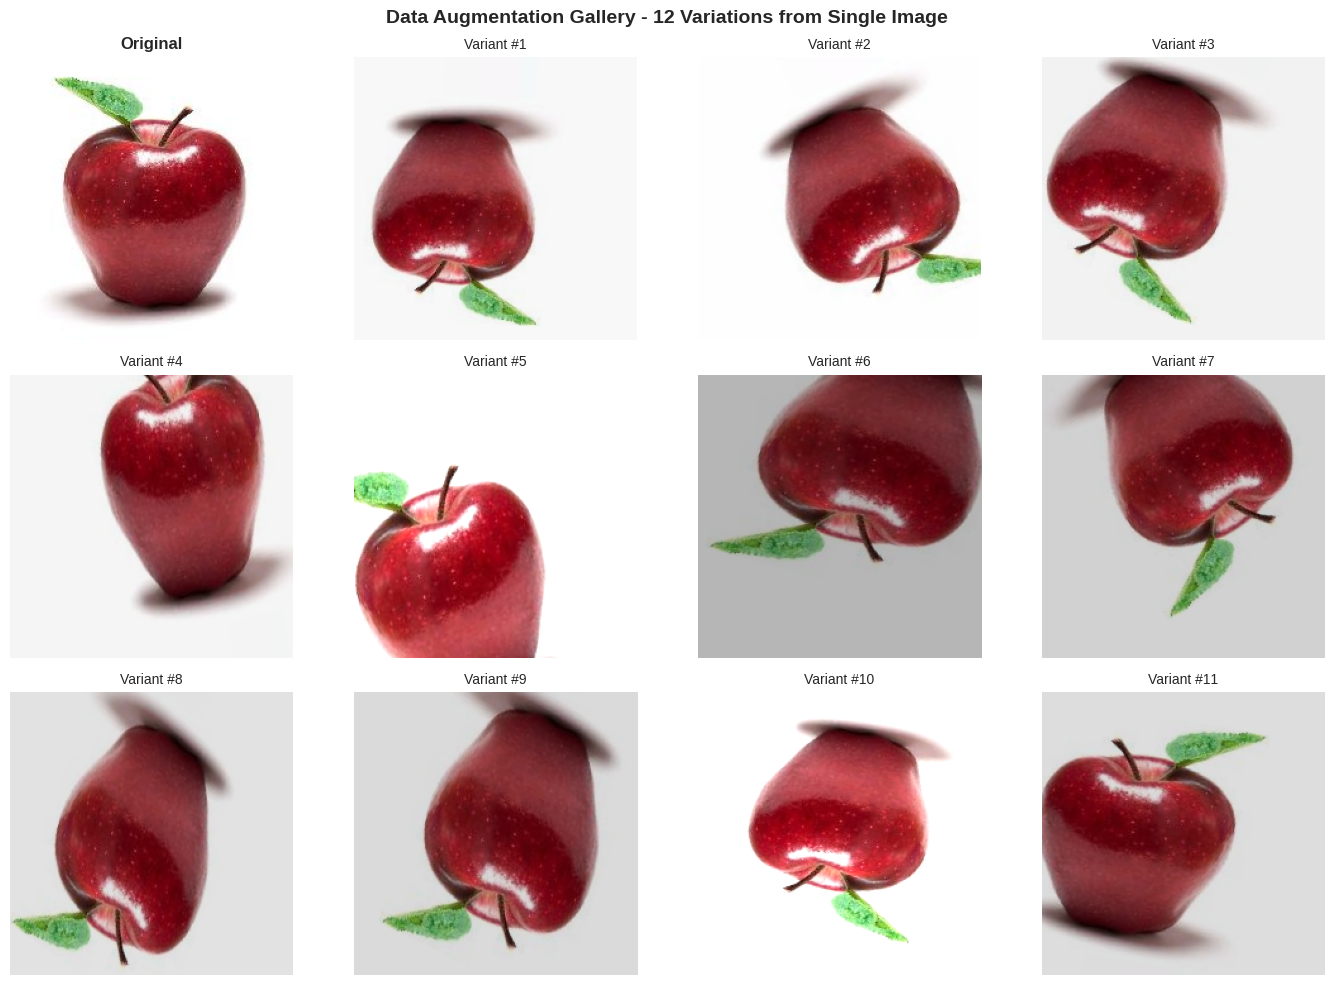

✓ Saved: 09_augmentation_gallery.png


In [ ]:
# FIGURE: Augmentation gallery (12 variations)
if TF_AVAILABLE:
    fig, axes = plt.subplots(3, 4, figsize=(14, 10))
    fig.suptitle('Data Augmentation Gallery - 12 Variations from Single Image', fontsize=14, fontweight='bold')

    sample_img_path = train_df.iloc[0]['path']
    img = load_img(sample_img_path, target_size=IMG_SIZE)
    img_array = img_to_array(img)
    img_array = img_array.reshape((1,) + img_array.shape)

    axes[0, 0].imshow(img_array[0].astype('uint8'))
    axes[0, 0].set_title('Original', fontsize=12, fontweight='bold')
    axes[0, 0].axis('off')

    aug_iter = datagen.flow(img_array, batch_size=1)
    for i in range(1, 12):
        aug_img = next(aug_iter)[0].astype('uint8')
        row = i // 4
        col = i % 4
        axes[row, col].imshow(aug_img)
        axes[row, col].set_title(f'Variant #{i}', fontsize=10)
        axes[row, col].axis('off')

    plt.tight_layout()
    plt.savefig('/kaggle/working/visualizations/09_augmentation_gallery.png', dpi=200, bbox_inches='tight')
    plt.show()
    print("✓ Saved: 09_augmentation_gallery.png")

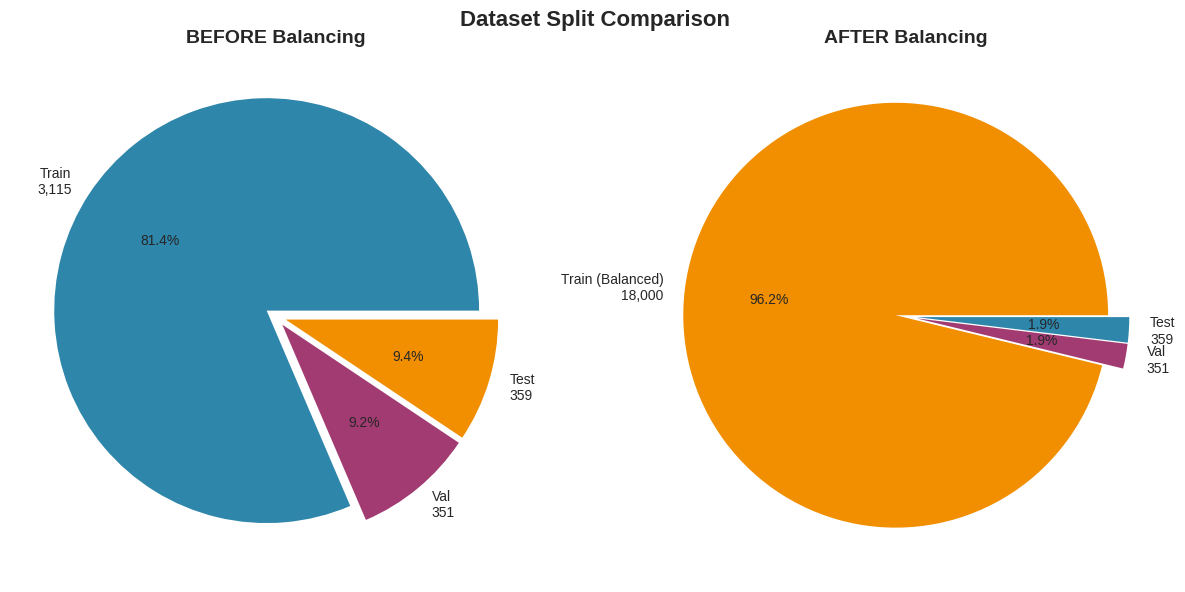

✓ Saved: 10_split_comparison.png


In [ ]:
# FIGURE: Pie chart comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Before pie
ax1 = axes[0]
before_pie_data = [total_before, len(val_df), len(test_df)]
before_pie_labels = [f'Train\n{total_before:,}', f'Val\n{len(val_df):,}', f'Test\n{len(test_df):,}']
ax1.pie(before_pie_data, labels=before_pie_labels, autopct='%1.1f%%', colors=['#2E86AB', '#A23B72', '#F18F01'], explode=(0.05, 0.05, 0.05))
ax1.set_title('BEFORE Balancing', fontsize=14, fontweight='bold')

# After pie
ax2 = axes[1]
after_pie_data = [total_after, len(val_df), len(test_df)]
after_pie_labels = [f'Train (Balanced)\n{total_after:,}', f'Val\n{len(val_df):,}', f'Test\n{len(test_df):,}']
ax2.pie(after_pie_data, labels=after_pie_labels, autopct='%1.1f%%', colors=['#F18F01', '#A23B72', '#2E86AB'], explode=(0.05, 0.05, 0.05))
ax2.set_title('AFTER Balancing', fontsize=14, fontweight='bold')

plt.suptitle('Dataset Split Comparison', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/visualizations/10_split_comparison.png', dpi=200, bbox_inches='tight')
plt.show()
print("✓ Saved: 10_split_comparison.png")

## 9. Advanced Analysis - Color & Edge


9. ADVANCED ANALYSIS - Color Histograms & Edge Detection


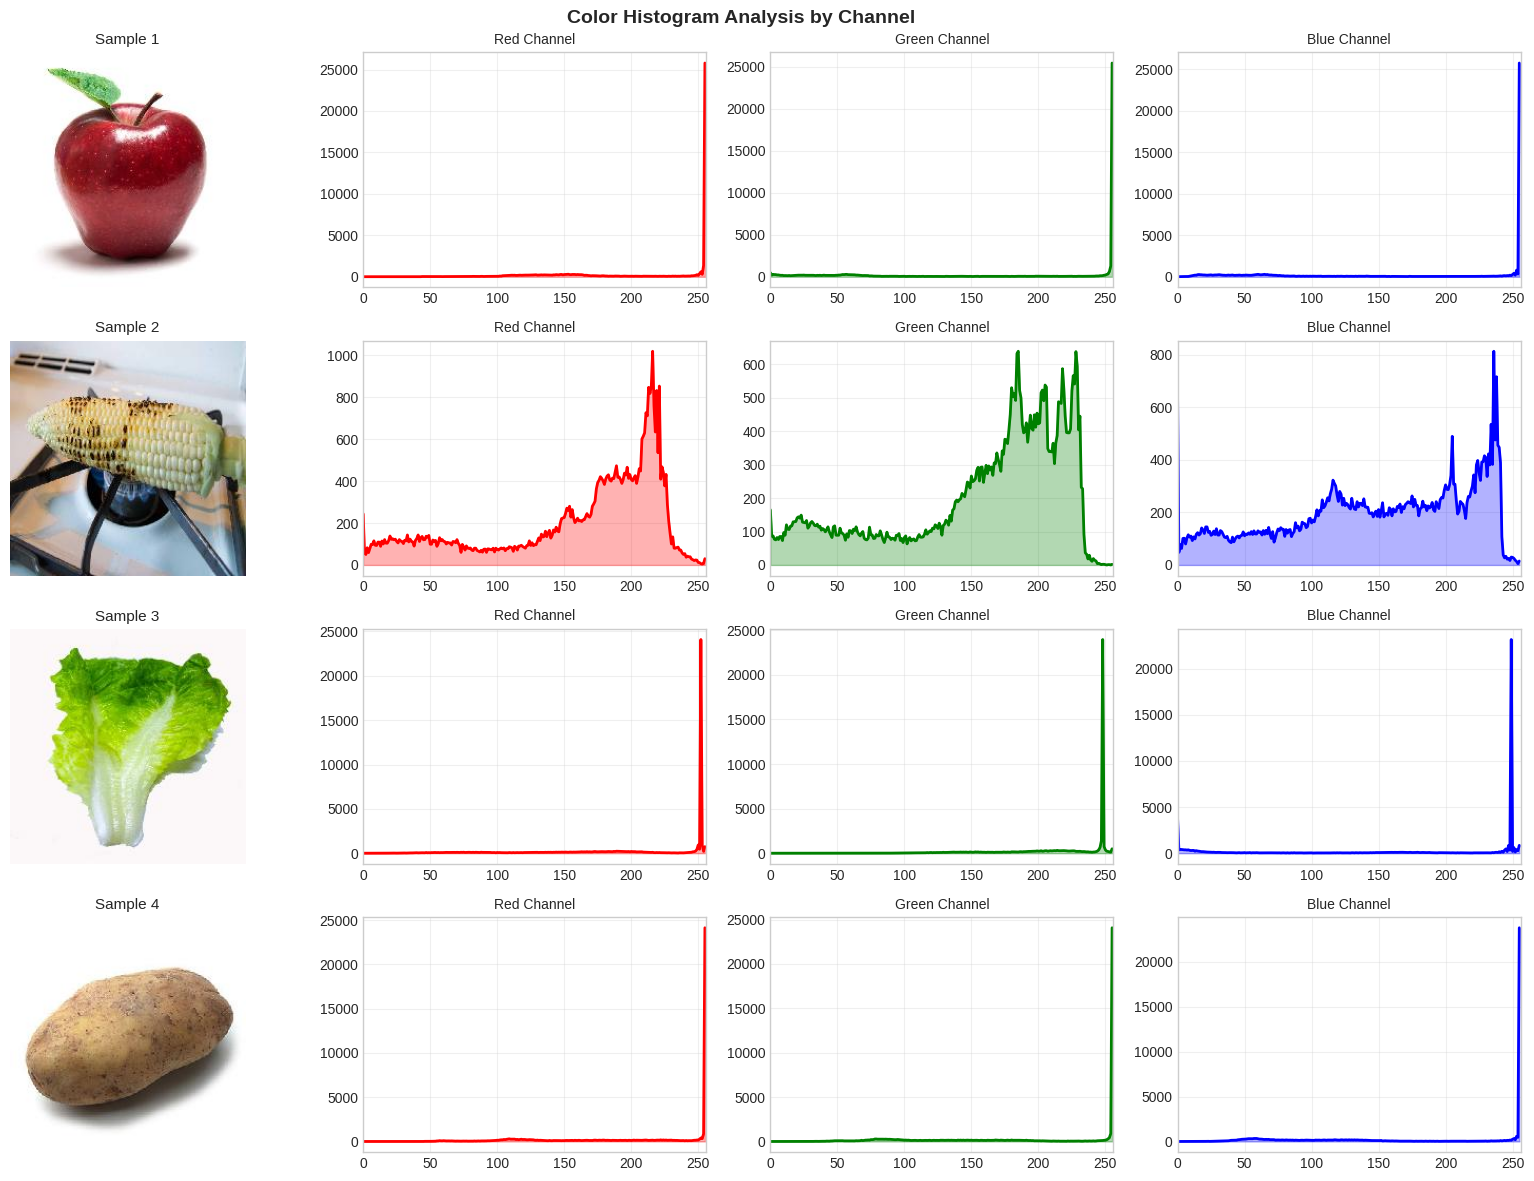

✓ Saved: 11_color_analysis.png


In [ ]:
print("\n" + "=" * 60)
print("9. ADVANCED ANALYSIS - Color Histograms & Edge Detection")
print("=" * 60)

# Color histogram analysis
def plot_color_histograms(df, num_samples=4):
    fig, axes = plt.subplots(num_samples, 4, figsize=(16, num_samples*3))

    for i in range(min(num_samples, len(df))):
        img_path = df.iloc[i*max(1, len(df)//num_samples)]['path']
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img_resized = cv2.resize(img, IMG_SIZE)

        axes[i, 0].imshow(img_resized)
        axes[i, 0].set_title(f'Sample {i+1}', fontsize=11)
        axes[i, 0].axis('off')

        color_names = ('Red', 'Green', 'Blue')
        for j, (color, name) in enumerate(zip(('red', 'green', 'blue'), color_names)):
            histr = cv2.calcHist([img_resized], [j], None, [256], [0, 256])
            axes[i, j+1].plot(histr, color=color, linewidth=2)
            axes[i, j+1].set_xlim([0, 256])
            axes[i, j+1].set_title(f'{name} Channel', fontsize=10)
            axes[i, j+1].grid(True, alpha=0.3)
            axes[i, j+1].fill_between(range(256), histr.flatten(), alpha=0.3, color=color)

    plt.suptitle('Color Histogram Analysis by Channel', fontsize=14, fontweight='bold')
    plt.tight_layout()
    return fig

fig = plot_color_histograms(train_df, num_samples=4)
plt.savefig('/kaggle/working/visualizations/11_color_analysis.png', dpi=200, bbox_inches='tight')
plt.show()
print("✓ Saved: 11_color_analysis.png")

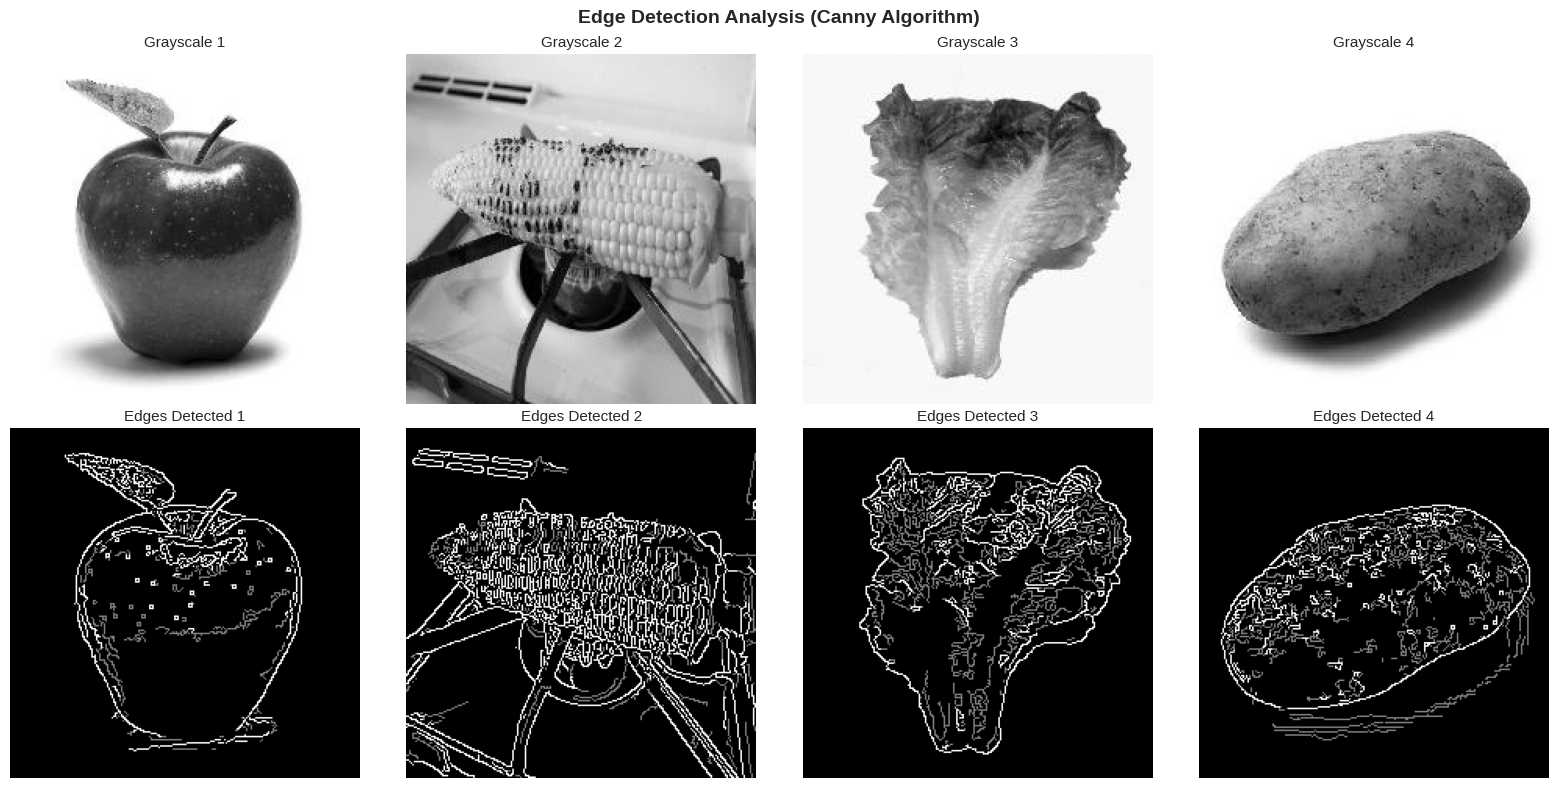

✓ Saved: 12_edge_detection.png


In [ ]:
# Edge detection visualization
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Edge Detection Analysis (Canny Algorithm)', fontsize=14, fontweight='bold')

for i in range(4):
    img_path = train_df.iloc[i*max(1, len(train_df)//4)]['path']
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, IMG_SIZE)

    axes[0, i].imshow(img, cmap='gray')
    axes[0, i].set_title(f'Grayscale {i+1}', fontsize=11)
    axes[0, i].axis('off')

    edges_low = cv2.Canny(img, 50, 150)
    edges_high = cv2.Canny(img, 100, 200)
    edges_combined = cv2.addWeighted(edges_low, 0.5, edges_high, 0.5, 0)

    axes[1, i].imshow(edges_combined, cmap='gray')
    axes[1, i].set_title(f'Edges Detected {i+1}', fontsize=11)
    axes[1, i].axis('off')

plt.tight_layout()
plt.savefig('/kaggle/working/visualizations/12_edge_detection.png', dpi=200, bbox_inches='tight')
plt.show()
print("✓ Saved: 12_edge_detection.png")

## 10. Final Report - Comprehensive Data Summary

In [ ]:
print("\n" + "=" * 60)
print("10. FINAL REPORT - DATA PIPELINE SUMMARY")
print("=" * 60)

# Create comprehensive report
report = f"""
{'='*70}
FRUIT & VEGETABLE DATASET - COMPREHENSIVE DATA PIPELINE REPORT (BALANCED)
{'='*70}
Generated: {pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S')}

{'='*70}
1. DATASET OVERVIEW
{'='*70}
Total Classes: {NUM_CLASSES}
Total Original Images: {len(full_df):,}
  ├── Training:   {len(train_df):,} ({len(train_df)/len(full_df)*100:.1f}%) # Note: This train_df is now the augmented one
  ├── Validation: {len(val_df):,} ({len(val_df)/len(full_df)*100:.1f}%) # Keep original count
  └── Test:       {len(test_df):,} ({len(test_df)/len(full_df)*100:.1f}%) # Keep original count

{'='*70}
2. CLASS BALANCING STRATEGY
{'='*70}
Target Images per Class: {TARGET_IMAGES_PER_CLASS}
Total Target Training Images: {TARGET_IMAGES_PER_CLASS * NUM_CLASSES:,}

BALANCING SUMMARY:
  Classes that NEED augmentation: {sum(1 for c in class_names if augmentation_needed[c]['original'] < TARGET_IMAGES_PER_CLASS)}
  Classes that are ALREADY SUFFICIENT: {sum(1 for c in class_names if augmentation_needed[c]['original'] >= TARGET_IMAGES_PER_CLASS)}

BEFORE BALANCING:
  Total training images (original): {sum(augmentation_needed[c]['original'] for c in class_names):,}
  Mean images per class: {np.mean([augmentation_needed[c]['original'] for c in class_names]):.1f}
  Median images per class: {np.median([augmentation_needed[c]['original'] for c in class_names]):.0f}
  Coefficient of Variation (CV): {cv_before:.4f}
  → {'IMBALANCED' if cv_before > 0.5 else 'BALANCED'} dataset

AFTER BALANCING (images saved to disk):
  Total training images: {total_after:,}
  Mean images per class: {np.mean(after_counts_adj):.1f}
  Median images per class: {np.median(after_counts_adj):.0f}
  Coefficient of Variation (CV): {cv_after:.4f}
  → {'BALANCED' if cv_after < 0.1 else 'Still imbalanced'} dataset

{'='*70}
3. AUGMENTATION DETAILS PER CLASS
{'='*70}
{chr(10).join([f'  {c:<20}: {augmentation_needed[c]["original"]:>4} → {augmentation_needed[c]["target"]:>4} images (×{augmentation_needed[c]["multiplier"]:.1f})'
               for c in class_names[:10]])}
  ... and {len(class_names)-10} more classes

{'='*70}
4. IMAGE CHARACTERISTICS
{'='*70}
Resolution Range: {full_df['width'].min()}x{full_df['height'].min()} to {full_df['width'].max()}x{full_df['height'].max()}
Average Resolution: {full_df['width'].mean():.0f}x{full_df['height'].mean():.0f}
Aspect Ratio - Mean: {full_df['aspect_ratio'].mean():.2f}

Color Modes:
{chr(10).join([f'  - {mode}: {count:,} images ({count/len(full_df)*100:.1f}%)' for mode, count in full_df['channels'].value_counts().items()])}

File Formats:
{chr(10).join([f'  - {fmt}: {count:,} images ({count/len(full_df)*100:.1f}%)' for fmt, count in full_df['format'].value_counts().items()])}

{'='*70}
5. PREPROCESSING & AUGMENTATION PARAMETERS
{'='*70}
Target Image Size: {IMG_SIZE[0]}x{IMG_SIZE[1]}
Normalization: {NORMALIZATION}
Augmentation Parameters:
{chr(10).join([f'  - {key:20s}: {value}' for key, value in augmentation_params.items()])}

{'='*70}
6. GENERATED FILES
{'='*70}
📁 /kaggle/working/visualizations/
├── 01_data_overview.png              - Split distribution, resolution, aspect ratio
├── 02_class_analysis_before.png      - Class analysis BEFORE balancing
├── 03_format_distribution.png        - Color mode & file format by split
├── 04_sample_images.png              - Sample images per class
├── 05_preprocessing_demo.png         - Original vs Preprocessed comparison
├── 06_balancing_comparison.png       - BEFORE vs AFTER balancing (bar chart)
├── 07_distribution_comparison.png    - Distribution histogram comparison
├── 08_augmentation_demo.png          - Augmentation for a class with few samples
├── 09_augmentation_gallery.png       - 12 augmentation variations gallery
├── 10_split_comparison.png           - Dataset split comparison pie charts
├── 11_color_analysis.png             - RGB color histograms analysis
└── 12_edge_detection.png             - Edge detection visualization

📁 /kaggle/working/augmented_train_data/ (Contains {len(train_df):,} augmented training images saved to disk)
📄 /kaggle/working/image_metadata.csv - Complete image metadata
📄 /kaggle/working/balancing_report.txt - This report
📄 /kaggle/working/augmentation_needs.csv - Augmentation details per class

{'='*70}
7. RECOMMENDATIONS FOR TRAINING
{'='*70}
✓ Dataset is now BALANCED - no need for class weights!
✓ Images for training are already augmented and saved to disk in `{AUGMENTED_TRAIN_DIR}`.
✓ Use only preprocessing (e.g., MobileNetV2 preprocessing_function) with `ImageDataGenerator` for training.
✓ Resize all images to {IMG_SIZE[0]}x{IMG_SIZE[1]} for consistency
✓ Use {'ImageNet normalization' if NORMALIZATION == 'imagenet' else 'min-max scaling'}
✓ Recommended batch size: 32-64
✓ Use early stopping to prevent overfitting

{'='*70}
✅ DATA PIPELINE COMPLETE - READY FOR TRAINING
{'='*70}
"""

print(report)

# Save report
with open('/kaggle/working/balancing_report.txt', 'w') as f:
    f.write(report)

# Save processed data info
full_df.to_csv('/kaggle/working/image_metadata.csv', index=False)
print("✓ Saved: image_metadata.csv")
print("✓ Saved: balancing_report.txt")

# Save augmentation needs as CSV
augmentation_df = pd.DataFrame([
    {
        'class': c,
        'original_count': augmentation_needed[c]['original'],
        'target_count': augmentation_needed[c]['target'],
        'needed_augmentations': augmentation_needed[c]['needed'],
        'multiplier': augmentation_needed[c]['multiplier']
    }
    for c in class_names
])
augmentation_df.to_csv('/kaggle/working/augmentation_needs.csv', index=False)
print("✓ Saved: augmentation_needs.csv")

# Print summary of saved files
print("\n" + "=" * 60)
print("✅ DATA PIPELINE COMPLETE - NO TRAINING PERFORMED")
print("=" * 60)
print("\n📁 OUTPUT FILES:")
print("   Visualizations: /kaggle/working/visualizations/ (12 files)")
print(f"   Augmented Training Data: {AUGMENTED_TRAIN_DIR} ({len(train_df):,} images)")
print("   Metadata: /kaggle/working/image_metadata.csv")
print("   Report: /kaggle/working/balancing_report.txt")
print("   Augmentation Needs: /kaggle/working/augmentation_needs.csv")
print("\n📊 BALANCING SUMMARY:")
print(f"   Total Classes: {NUM_CLASSES}")
print(f"   Target per class: {TARGET_IMAGES_PER_CLASS}")
print(f"   Training BEFORE (original): {sum(augmentation_needed[c]['original'] for c in class_names):,} images")
print(f"   Training AFTER (saved augmented): {total_after:,} images")
print(f"   Increase: {total_after - sum(augmentation_needed[c]['original'] for c in class_names):,} images ({((total_after/sum(augmentation_needed[c]['original'] for c in class_names))-1)*100:.1f}%) ")
print(f"   CV BEFORE: {cv_before:.4f}")
print(f"   CV AFTER (saved augmented): {cv_after:.4f}")
print("\n" + "=" * 60)


10. FINAL REPORT - DATA PIPELINE SUMMARY

FRUIT & VEGETABLE DATASET - COMPREHENSIVE DATA PIPELINE REPORT (BALANCED)
Generated: 2026-05-18 08:23:22

1. DATASET OVERVIEW
Total Classes: 36
Total Original Images: 3,825
  ├── Training:   18,000 (470.6%) # Note: This train_df is now the augmented one
  ├── Validation: 351 (9.2%) # Keep original count
  └── Test:       359 (9.4%) # Keep original count

2. CLASS BALANCING STRATEGY
Target Images per Class: 500
Total Target Training Images: 18,000

BALANCING SUMMARY:
  Classes that NEED augmentation: 36
  Classes that are ALREADY SUFFICIENT: 0

BEFORE BALANCING:
  Total training images (original): 3,115
  Mean images per class: 86.5
  Median images per class: 88
  Coefficient of Variation (CV): 0.1064
  → BALANCED dataset

AFTER BALANCING (images saved to disk):
  Total training images: 18,000
  Mean images per class: 500.0
  Median images per class: 500
  Coefficient of Variation (CV): 0.0000
  → BALANCED dataset

3. AUGMENTATION DETAILS PER C

## 11. Model Training Pipeline

In [ ]:
print("\n" + "=" * 60)
print("11. MODEL TRAINING PIPELINE")
print("=" * 60)

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# --- 1. Data Generators Setup ---
print("\nSetting up data generators...")

# train_datagen now only performs preprocessing as images are already augmented on disk
train_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input
)

# Validation and test data should not be augmented, only preprocessed.
val_test_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input
)

# Use flow_from_dataframe as we have pre-analyzed dataframes (train_df, val_df, test_df).
BATCH_SIZE = 32 # Can be adjusted

train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df, # This train_df now contains paths to augmented images in AUGMENTED_TRAIN_DIR
    x_col='path',
    y_col='class',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True,
    seed=42
)

validation_generator = val_test_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='path',
    y_col='class',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False # No need to shuffle validation data
)

test_generator = val_test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col='path',
    y_col='class',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False # No need to shuffle test data
)

print("Data generators created.")

# --- 2. Model Definition (Transfer Learning with MobileNetV2) ---
print("\nDefining MobileNetV2 based model...")

# Load pre-trained MobileNetV2 model without the top classification layer
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)
)

# Freeze the base model layers so they are not updated during training
base_model.trainable = False

# Add custom classification layers on top of the base model
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x) # Additional dense layer
x = Dropout(0.5)(x) # Dropout for regularization
predictions = Dense(NUM_CLASSES, activation='softmax')(x) # Final output layer

model = Model(inputs=base_model.input, outputs=predictions)

print("Model architecture defined.")
model.summary()



11. MODEL TRAINING PIPELINE

Setting up data generators...
Found 18000 validated image filenames belonging to 36 classes.
Found 351 validated image filenames belonging to 36 classes.
Found 359 validated image filenames belonging to 36 classes.
Data generators created.

Defining MobileNetV2 based model...
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Model architecture defined.


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,595,172 (9.90 MB)

 Trainable params: 337,188 (1.29 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

### 11.1 Model Compilation and Training

In [ ]:
print("\nCompiling model...")

# --- 3. Model Compilation ---
model.compile(
    optimizer=Adam(learning_rate=0.0001), # Lower learning rate for fine-tuning/transfer learning
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled.")

# --- 4. Model Training ---
print("\nStarting model training...")

# Callbacks for better training control
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5, # Number of epochs with no improvement after which training will be stopped.
    restore_best_weights=True
)

model_checkpoint = ModelCheckpoint(
    filepath='/kaggle/working/best_model.keras',
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

# Train the model
history = model.fit(
    train_generator,
    epochs=20, # Set a reasonable number of epochs, EarlyStopping will prevent overfitting
    validation_data=validation_generator,
    callbacks=[early_stopping, model_checkpoint]
)

print("Model training complete. Best model saved to /kaggle/working/best_model.keras")


Compiling model...
Model compiled.

Starting model training...
Epoch 1/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.2169 - loss: 3.0512
Epoch 1: val_accuracy improved from None to 0.78063, saving model to /kaggle/working/best_model.keras

Epoch 1: finished saving model to /kaggle/working/best_model.keras
563/563 ━━━━━━━━━━━━━━━━━━━━ 96s 136ms/step - accuracy: 0.3736 - loss: 2.3804 - val_accuracy: 0.7806 - val_loss: 0.8837
Epoch 2/20
562/563 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.6298 - loss: 1.3092
Epoch 2: val_accuracy improved from 0.78063 to 0.87179, saving model to /kaggle/working/best_model.keras

Epoch 2: finished saving model to /kaggle/working/best_model.keras
563/563 ━━━━━━━━━━━━━━━━━━━━ 37s 66ms/step - accuracy: 0.6564 - loss: 1.2019 - val_accuracy: 0.8718 - val_loss: 0.5075
Epoch 3/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.7179 - loss: 0.9484
Epoch 3: val_accuracy improved from 0.87179 to 0.89744, saving model to /kaggle/working/best_

### 11.2 Model Evaluation and Visualization


12. MODEL EVALUATION AND VISUALIZATION

Evaluating model on the test set...
12/12 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.9499 - loss: 0.1755
Test Loss: 0.1755
Test Accuracy: 0.9499

Plotting training history...


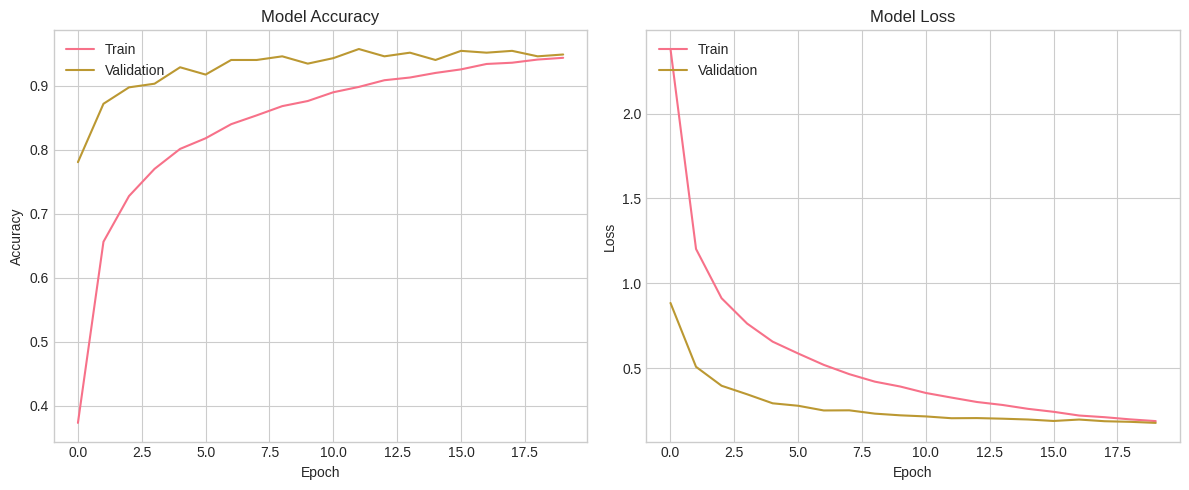

✓ Saved: 13_training_history.png


In [ ]:
print("\n" + "=" * 60)
print("12. MODEL EVALUATION AND VISUALIZATION")
print("=" * 60)

# --- 5. Model Evaluation ---
print("\nEvaluating model on the test set...")
loss, accuracy = model.evaluate(test_generator)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

# --- 6. Plot Training History ---
print("\nPlotting training history...")

plt.figure(figsize=(12, 5))

# Plot training & validation accuracy values
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.grid(True)

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.grid(True)

plt.tight_layout()
plt.savefig('/kaggle/working/visualizations/13_training_history.png', dpi=200, bbox_inches='tight')
plt.show()
print("✓ Saved: 13_training_history.png")


13. CONFUSION MATRIX AND CLASSIFICATION REPORT
12/12 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step


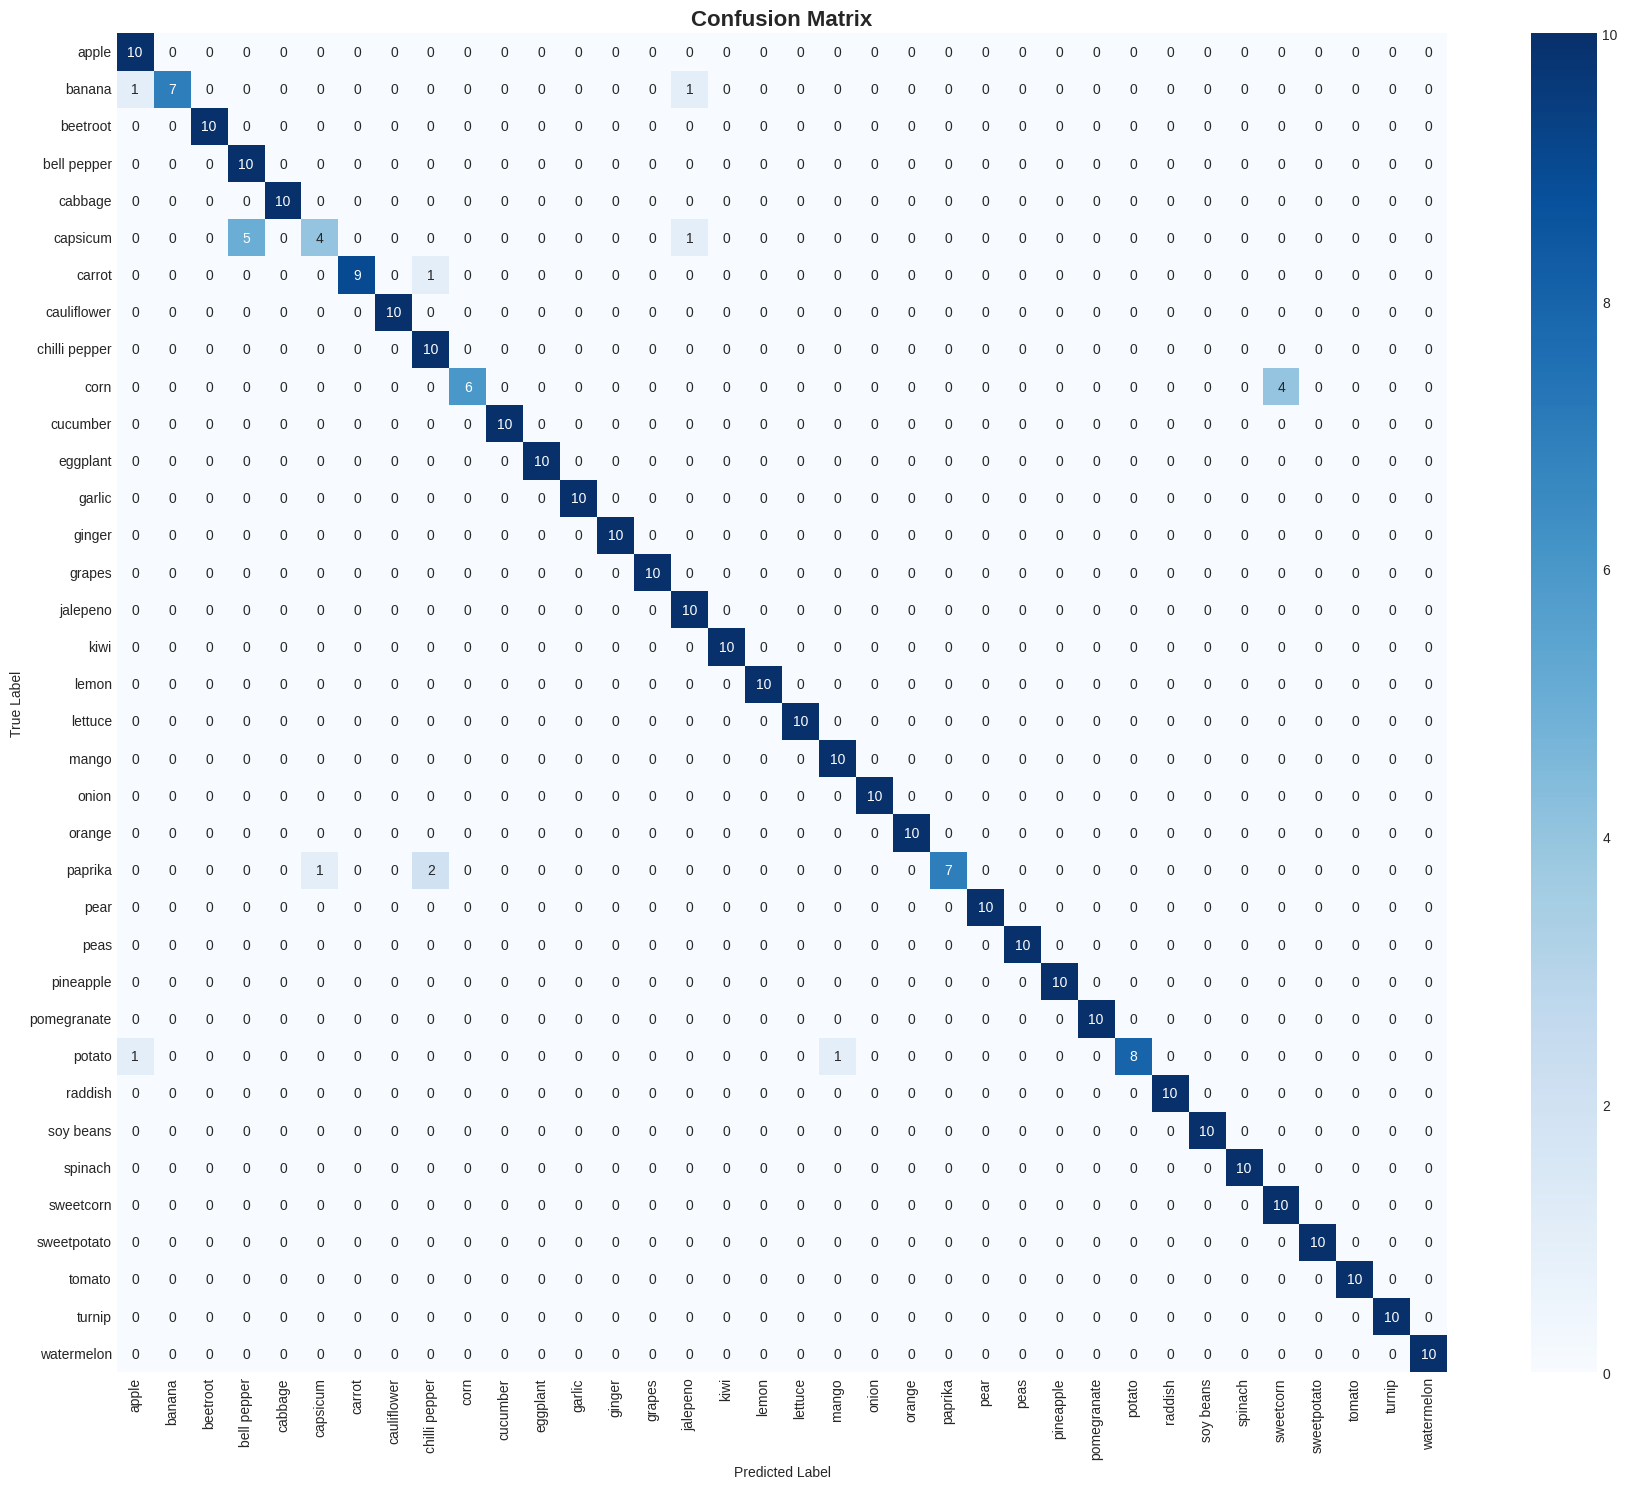

✓ Saved: 14_confusion_matrix.png

Classification Report:
               precision    recall  f1-score   support

        apple     0.8333    1.0000    0.9091        10
       banana     1.0000    0.7778    0.8750         9
     beetroot     1.0000    1.0000    1.0000        10
  bell pepper     0.6667    1.0000    0.8000        10
      cabbage     1.0000    1.0000    1.0000        10
     capsicum     0.8000    0.4000    0.5333        10
       carrot     1.0000    0.9000    0.9474        10
  cauliflower     1.0000    1.0000    1.0000        10
chilli pepper     0.7692    1.0000    0.8696        10
         corn     1.0000    0.6000    0.7500        10
     cucumber     1.0000    1.0000    1.0000        10
     eggplant     1.0000    1.0000    1.0000        10
       garlic     1.0000    1.0000    1.0000        10
       ginger     1.0000    1.0000    1.0000        10
       grapes     1.0000    1.0000    1.0000        10
     jalepeno     0.8333    1.0000    0.9091        10
       

In [ ]:
print("\n" + "=" * 60)
print("13. CONFUSION MATRIX AND CLASSIFICATION REPORT")
print("=" * 60)

from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Get true labels and predictions from the test generator
test_labels = test_generator.classes
predictions = model.predict(test_generator)
predicted_classes = np.argmax(predictions, axis=1)

# Map generator indices to class names
label_map = (test_generator.class_indices)
label_map = dict((v,k) for k,v in label_map.items())
class_names_ordered = [label_map[i] for i in range(NUM_CLASSES)]

# 1. Confusion Matrix
cm = confusion_matrix(test_labels, predicted_classes)

plt.figure(figsize=(18, 15))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names_ordered, yticklabels=class_names_ordered)
plt.title('Confusion Matrix', fontsize=16, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('/kaggle/working/visualizations/14_confusion_matrix.png', dpi=200, bbox_inches='tight')
plt.show()
print("✓ Saved: 14_confusion_matrix.png")

# 2. Classification Report
report = classification_report(test_labels, predicted_classes, target_names=class_names_ordered, digits=4)
print("\nClassification Report:")
print(report)

with open('/kaggle/working/classification_report.txt', 'w') as f:
    f.write(report)
print("✓ Saved: classification_report.txt")

## 14. Sample Predictions: Correct vs. Incorrect

Let's visualize some examples of the model's predictions to understand its performance more intuitively. We will pick a few images where the model predicted correctly and a few where it made mistakes.


14. SAMPLE PREDICTIONS
12/12 ━━━━━━━━━━━━━━━━━━━━ 11s 933ms/step


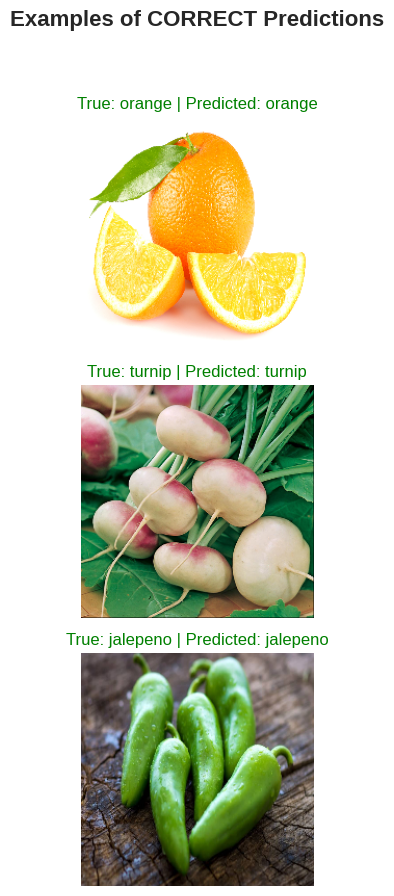

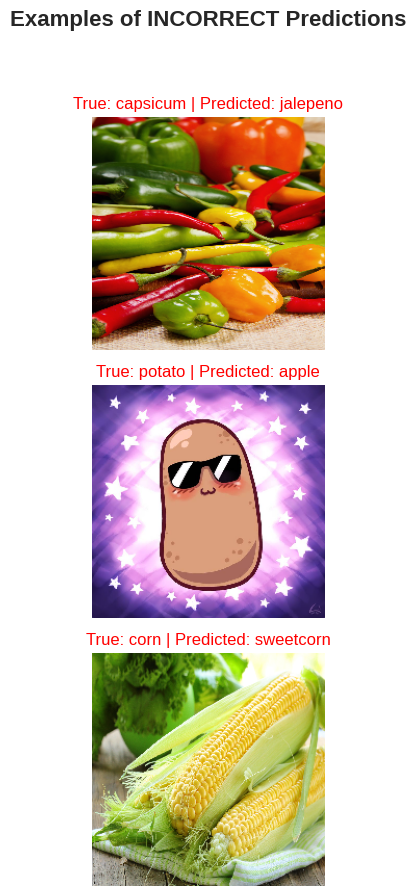


SAMPLE PREDICTIONS COMPLETE


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import cv2

print("\n" + "=" * 60)
print("14. SAMPLE PREDICTIONS")
print("=" * 60)

# Get true labels and predicted labels from the test generator
true_labels_indices = test_generator.classes
predicted_labels_indices = np.argmax(model.predict(test_generator), axis=1)

# Map generator indices to class names (already available in class_names_ordered)
# class_names_ordered = [label_map[i] for i in range(NUM_CLASSES)]

# Get file paths for test images
test_image_paths = test_df['path'].tolist()

correct_predictions_indices = np.where(true_labels_indices == predicted_labels_indices)[0]
incorrect_predictions_indices = np.where(true_labels_indices != predicted_labels_indices)[0]

def display_predictions(indices, title, num_samples=5):
    plt.figure(figsize=(15, 3 * num_samples))
    plt.suptitle(title, fontsize=16, fontweight='bold', y=1.02)

    for i, idx in enumerate(np.random.choice(indices, min(num_samples, len(indices)), replace=False)):
        img_path = test_image_paths[idx]
        true_class = class_names_ordered[true_labels_indices[idx]]
        predicted_class = class_names_ordered[predicted_labels_indices[idx]]

        img = cv2.imread(img_path)
        if img is None:
            print(f"Could not load image: {img_path}")
            continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, IMG_SIZE)

        plt.subplot(num_samples, 1, i + 1)
        plt.imshow(img)
        plt.title(f"True: {true_class} | Predicted: {predicted_class}",
                  color='green' if true_class == predicted_class else 'red')
        plt.axis('off')
    plt.tight_layout(rect=[0, 0.03, 1, 0.98])
    plt.show()

# Display some correct predictions
display_predictions(correct_predictions_indices, 'Examples of CORRECT Predictions', num_samples=3)

# Display some incorrect predictions
display_predictions(incorrect_predictions_indices, 'Examples of INCORRECT Predictions', num_samples=3)

print("\n" + "=" * 60)
print("SAMPLE PREDICTIONS COMPLETE")
print("=" * 60)

In [ ]:
import shutil

output_filename = '/kaggle/working/visualizations_archive'
root_dir = '/kaggle/working/visualizations'

# Create a zip archive of the visualizations directory
shutil.make_archive(output_filename, 'zip', root_dir)

print(f"Successfully created a zip archive at: {output_filename}.zip")

Successfully created a zip archive at: /kaggle/working/visualizations_archive.zip


## 15. Export Model ke TFLite (Mobile Deployment)

Mengkonversi model Keras ke format **TensorFlow Lite (.tflite)** agar bisa dijalankan di perangkat mobile (Android/iOS) dengan performa ringan dan efisien.

Tersedia 3 versi:
- `model_float32.tflite` — akurasi penuh, ukuran lebih besar
- `model_float16.tflite` — ukuran ~2x lebih kecil, akurasi hampir sama
- `model_int8.tflite` — ukuran paling kecil, cocok untuk edge device (butuh representatif dataset)

In [ ]:
import tensorflow as tf
import numpy as np
import os

print("=" * 60)
print("15. EXPORT MODEL KE TFLITE")
print("=" * 60)

# Buat direktori output
tflite_dir = '/kaggle/working/tflite_models'
os.makedirs(tflite_dir, exist_ok=True)

# Load best model yang sudah disimpan
print("\n[1/4] Loading best model...")
best_model = tf.keras.models.load_model('/kaggle/working/best_model.keras')
print(f"  ✓ Model loaded: {best_model.input_shape} → {best_model.output_shape}")

# ─────────────────────────────────────────────
# VERSI 1: Float32 (default, akurasi penuh)
# ─────────────────────────────────────────────
print("\n[2/4] Konversi Float32...")
converter_f32 = tf.lite.TFLiteConverter.from_keras_model(best_model)
tflite_f32 = converter_f32.convert()

path_f32 = os.path.join(tflite_dir, 'model_float32.tflite')
with open(path_f32, 'wb') as f:
    f.write(tflite_f32)
size_f32 = os.path.getsize(path_f32) / (1024 * 1024)
print(f"  ✓ Disimpan: model_float32.tflite  ({size_f32:.2f} MB)")

# ─────────────────────────────────────────────
# VERSI 2: Float16 (ukuran ~50% lebih kecil)
# ─────────────────────────────────────────────
print("\n[3/4] Konversi Float16...")
converter_f16 = tf.lite.TFLiteConverter.from_keras_model(best_model)
converter_f16.optimizations = [tf.lite.Optimize.DEFAULT]
converter_f16.target_spec.supported_types = [tf.float16]
tflite_f16 = converter_f16.convert()

path_f16 = os.path.join(tflite_dir, 'model_float16.tflite')
with open(path_f16, 'wb') as f:
    f.write(tflite_f16)
size_f16 = os.path.getsize(path_f16) / (1024 * 1024)
print(f"  ✓ Disimpan: model_float16.tflite  ({size_f16:.2f} MB)")

# ─────────────────────────────────────────────
# VERSI 3: Int8 Quantization (ukuran terkecil)
# ─────────────────────────────────────────────
print("\n[4/4] Konversi Int8 (quantization)...")

def representative_dataset_gen():
    """Ambil sampel dari validation set untuk kalibrasi int8."""
    val_test_datagen_calib = tf.keras.preprocessing.image.ImageDataGenerator(
        preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input
    )
    calib_gen = val_test_datagen_calib.flow_from_dataframe(
        dataframe=val_df.sample(min(100, len(val_df)), random_state=42),
        x_col='path',
        y_col='class',
        target_size=IMG_SIZE,
        batch_size=1,
        class_mode='categorical',
        shuffle=False
    )
    for i, (img_batch, _) in enumerate(calib_gen):
        yield [img_batch.astype(np.float32)]
        if i >= 99:
            break

converter_int8 = tf.lite.TFLiteConverter.from_keras_model(best_model)
converter_int8.optimizations = [tf.lite.Optimize.DEFAULT]
converter_int8.representative_dataset = representative_dataset_gen
converter_int8.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter_int8.inference_input_type  = tf.uint8
converter_int8.inference_output_type = tf.uint8
tflite_int8 = converter_int8.convert()

path_int8 = os.path.join(tflite_dir, 'model_int8.tflite')
with open(path_int8, 'wb') as f:
    f.write(tflite_int8)
size_int8 = os.path.getsize(path_int8) / (1024 * 1024)
print(f"  ✓ Disimpan: model_int8.tflite      ({size_int8:.2f} MB)")

# ─────────────────────────────────────────────
# Ringkasan ukuran file
# ─────────────────────────────────────────────
print("\n" + "=" * 60)
print("RINGKASAN UKURAN FILE TFLITE")
print("=" * 60)
print(f"  Float32 : {size_f32:.2f} MB  (akurasi penuh)")
print(f"  Float16 : {size_f16:.2f} MB  ({100*(1-size_f16/size_f32):.0f}% lebih kecil dari float32)")
print(f"  Int8    : {size_int8:.2f} MB  ({100*(1-size_int8/size_f32):.0f}% lebih kecil dari float32)")
print("\n✅ Semua model TFLite berhasil disimpan di:", tflite_dir)


15. EXPORT MODEL KE TFLITE

[1/4] Loading best model...
  ✓ Model loaded: (None, 224, 224, 3) → (None, 36)

[2/4] Konversi Float32...
Saved artifact at '/tmp/tmpd91xrnyh'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 36), dtype=tf.float32, name=None)
Captures:
  136088255131152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136088255126736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136088255129040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136088255134800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136088255131728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136088255132304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136088255132112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136088255132496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136088255128656: Ten

In [ ]:
# ─────────────────────────────────────────────
# Simpan label map (index → nama kelas)
# Wajib disertakan bersama file .tflite di app mobile
# ─────────────────────────────────────────────
import json

label_map_path = os.path.join(tflite_dir, 'labels.txt')
with open(label_map_path, 'w') as f:
    for idx, name in enumerate(class_names_ordered):
        f.write(f"{name}\n")

label_json_path = os.path.join(tflite_dir, 'labels.json')
with open(label_json_path, 'w') as f:
    json.dump({str(i): name for i, name in enumerate(class_names_ordered)}, f, indent=2)

print(f"✓ Saved: labels.txt   — untuk Android (TFLite Task Library)")
print(f"✓ Saved: labels.json  — untuk Flutter / React Native")

# ─────────────────────────────────────────────
# Validasi: Test inference dengan Float32 model
# ─────────────────────────────────────────────
print("\n" + "=" * 60)
print("VALIDASI INFERENCE TFLITE (Float32)")
print("=" * 60)

interpreter = tf.lite.Interpreter(model_path=path_f32)
interpreter.allocate_tensors()

input_details  = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print(f"Input  shape : {input_details[0]['shape']}  dtype: {input_details[0]['dtype']}")
print(f"Output shape : {output_details[0]['shape']}  dtype: {output_details[0]['dtype']}")

# Ambil satu gambar test sebagai contoh
sample_path = test_df.iloc[0]['path']
from PIL import Image
sample_img = Image.open(sample_path).resize(IMG_SIZE)
sample_arr = np.array(sample_img, dtype=np.float32)
sample_arr = tf.keras.applications.mobilenet_v2.preprocess_input(sample_arr)
sample_arr = np.expand_dims(sample_arr, axis=0)  # (1, H, W, 3)

interpreter.set_tensor(input_details[0]['index'], sample_arr)
interpreter.invoke()
output = interpreter.get_tensor(output_details[0]['index'])

top_idx  = np.argmax(output[0])
top_conf = output[0][top_idx] * 100
true_label = test_df.iloc[0]['class']

print(f"\nContoh prediksi:")
print(f"  Gambar   : {os.path.basename(sample_path)}")
print(f"  Label asli : {true_label}")
print(f"  Prediksi   : {class_names_ordered[top_idx]}  (confidence: {top_conf:.1f}%)")
match = '✅ BENAR' if class_names_ordered[top_idx] == true_label else '❌ SALAH'
print(f"  Hasil      : {match}")

# Top-5 predictions
top5_idx = np.argsort(output[0])[::-1][:5]
print("\nTop-5 Predictions:")
for rank, i in enumerate(top5_idx):
    print(f"  {rank+1}. {class_names_ordered[i]:<25} {output[0][i]*100:.2f}%")


✓ Saved: labels.txt   — untuk Android (TFLite Task Library)
✓ Saved: labels.json  — untuk Flutter / React Native

VALIDASI INFERENCE TFLITE (Float32)
Input  shape : [  1 224 224   3]  dtype: <class 'numpy.float32'>
Output shape : [ 1 36]  dtype: <class 'numpy.float32'>

Contoh prediksi:
  Gambar   : Image_4.jpg
  Label asli : apple
  Prediksi   : pear  (confidence: 36.0%)
  Hasil      : ❌ SALAH

Top-5 Predictions:
  1. pear                      35.98%
  2. apple                     24.39%
  3. paprika                   15.56%
  4. potato                    6.15%
  5. turnip                    3.34%


In [ ]:
# ─────────────────────────────────────────────
# Zip semua file TFLite untuk di-download
# ─────────────────────────────────────────────
import shutil

zip_path = '/kaggle/working/tflite_models_package'
shutil.make_archive(zip_path, 'zip', tflite_dir)

final_zip = zip_path + '.zip'
size_zip = os.path.getsize(final_zip) / (1024 * 1024)
print(f"\n📦 Package siap di-download:")
print(f"   {final_zip}  ({size_zip:.2f} MB)")
print("\nIsi package:")
print("   model_float32.tflite  — untuk produksi umum")
print("   model_float16.tflite  — rekomendasi untuk Android/iOS")
print("   model_int8.tflite     — untuk edge device / microcontroller")
print("   labels.txt            — untuk Android (TFLite Task Library)")
print("   labels.json           — untuk Flutter / React Native")
print("\n✅ DEPLOYMENT MOBILE SIAP!")
print("   Panduan integrasi:")
print("   - Android : https://www.tensorflow.org/lite/android/quickstart")
print("   - iOS     : https://www.tensorflow.org/lite/ios/quickstart")
print("   - Flutter : https://pub.dev/packages/tflite_flutter")



📦 Package siap di-download:
   /kaggle/working/tflite_models_package.zip  (15.94 MB)

Isi package:
   model_float32.tflite  — untuk produksi umum
   model_float16.tflite  — rekomendasi untuk Android/iOS
   model_int8.tflite     — untuk edge device / microcontroller
   labels.txt            — untuk Android (TFLite Task Library)
   labels.json           — untuk Flutter / React Native

✅ DEPLOYMENT MOBILE SIAP!
   Panduan integrasi:
   - Android : https://www.tensorflow.org/lite/android/quickstart
   - iOS     : https://www.tensorflow.org/lite/ios/quickstart
   - Flutter : https://pub.dev/packages/tflite_flutter


#TESTNG

In [ ]:
# ══════════════════════════════════════════════════════
# CELL 1 — Setup: load TFLite model
# ══════════════════════════════════════════════════════
import tensorflow as tf
import numpy as np
import os, json, time, io
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from google.colab import files

# ─── Konfigurasi ───────────────────────────────────────
TFLITE_DIR  = '/kaggle/working/tflite_models'  # sesuaikan jika beda
MODEL_FILE  = 'model_float16.tflite'           # ganti ke float32 / int8 jika mau
LABELS_FILE = 'labels.txt'
IMG_SIZE    = (224, 224)
TOP_K       = 5

MODEL_PATH  = os.path.join(TFLITE_DIR, MODEL_FILE)
LABELS_PATH = os.path.join(TFLITE_DIR, LABELS_FILE)

# ─── Load labels ───────────────────────────────────────
def load_labels(path):
    if path.endswith('.json'):
        with open(path) as f:
            d = json.load(f)
        return [d[str(i)] for i in range(len(d))]
    with open(path) as f:
        return [l.strip() for l in f if l.strip()]

# ─── Load model ────────────────────────────────────────
print("Loading TFLite model...")
interpreter = tf.lite.Interpreter(model_path=MODEL_PATH)
interpreter.allocate_tensors()
input_details  = interpreter.get_input_details()
output_details = interpreter.get_output_details()
INPUT_DTYPE    = input_details[0]["dtype"]
labels         = load_labels(LABELS_PATH)

print(f"Model     : {MODEL_FILE}")
print(f"Input     : {input_details[0]['shape']}  dtype={INPUT_DTYPE.__name__}")
print(f"Kelas     : {len(labels)}")

# ─── Preprocessing ─────────────────────────────────────
def preprocess(img_pil):
    img = img_pil.convert("RGB").resize(IMG_SIZE, Image.LANCZOS)
    arr = np.array(img, dtype=np.float32)
    if INPUT_DTYPE == np.uint8:
        return np.expand_dims(arr.astype(np.uint8), axis=0)
    arr = (arr / 127.5) - 1.0
    return np.expand_dims(arr.astype(np.float32), axis=0)

# ─── Inference ─────────────────────────────────────────
def run_inference(img_pil):
    tensor = preprocess(img_pil)
    interpreter.set_tensor(input_details[0]["index"], tensor)
    t0 = time.perf_counter()
    interpreter.invoke()
    latency = (time.perf_counter() - t0) * 1000
    out = interpreter.get_tensor(output_details[0]["index"])[0]
    if output_details[0]["dtype"] == np.uint8:
        sc, zp = output_details[0]["quantization"]
        out = (out.astype(np.float32) - zp) * sc
    if out.max() > 1.0 or out.min() < 0.0:
        out = np.exp(out - out.max())
        out /= out.sum()
    top_idx  = np.argsort(out)[::-1][:TOP_K]
    top_conf = out[top_idx] * 100
    return [(labels[i], float(c)) for i, c in zip(top_idx, top_conf)], latency

# ─── Visualisasi ───────────────────────────────────────
def show_result(img_pil, results, latency, filename="gambar"):
    top_label, top_conf = results[0]
    conf_color = "#27ae60" if top_conf >= 70 else "#f39c12" if top_conf >= 40 else "#e74c3c"

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.patch.set_facecolor("#1a1a2e")

    # Kiri: gambar asli
    ax_img = axes[0]
    ax_img.imshow(img_pil.convert("RGB"))
    ax_img.set_title(f"Gambar: {filename}", color="white", fontsize=10, pad=8)
    ax_img.axis("off")
    ax_img.set_facecolor("#1a1a2e")
    rect = mpatches.FancyBboxPatch((0,0), 1, 1, transform=ax_img.transAxes,
                                    linewidth=3, edgecolor=conf_color,
                                    boxstyle="round,pad=0.02", fill=False)
    ax_img.add_patch(rect)

    # Kanan: bar chart Top-K
    ax_bar = axes[1]
    ax_bar.set_facecolor("#16213e")
    y_pos       = np.arange(TOP_K)
    bars_data   = [r[1] for r in results]
    bars_label  = [r[0].replace("_", " ").title() for r in results]
    bar_colors  = [conf_color if i == 0 else "#4a4a8a" for i in range(TOP_K)]

    bars = ax_bar.barh(y_pos, bars_data, color=bar_colors, height=0.6, edgecolor="none")
    for bar, val, lbl in zip(bars, bars_data, bars_label):
        ax_bar.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
                    f"{val:.1f}%", va="center", ha="left", color="white",
                    fontsize=9, fontweight="bold")
        ax_bar.text(-0.5, bar.get_y() + bar.get_height()/2,
                    lbl, va="center", ha="right", color="#cccccc", fontsize=9)

    ax_bar.set_xlim(-22, 115)
    ax_bar.set_ylim(-0.5, TOP_K - 0.5)
    ax_bar.invert_yaxis()
    ax_bar.set_xticks([])
    ax_bar.set_yticks([])
    ax_bar.spines[:].set_visible(False)

    verdict = "YAKIN" if top_conf >= 70 else "RAGU" if top_conf >= 40 else "TIDAK YAKIN"
    ax_bar.set_title(
        f"Prediksi: {top_label.replace('_',' ').upper()}  ({top_conf:.1f}%) — {verdict}\n"
        f"Model: {MODEL_FILE}  |  Latency: {latency:.1f} ms",
        color="white", fontsize=11, pad=12
    )
    plt.tight_layout(pad=2)
    plt.show()

print("\nSetup selesai! Jalankan Cell 2 untuk upload gambar.")


Loading TFLite model...
Model     : model_float16.tflite
Input     : [  1 224 224   3]  dtype=float32
Kelas     : 36

Setup selesai! Jalankan Cell 2 untuk upload gambar.


Pilih gambar dari device kamu (jpg/png)...
Bisa pilih lebih dari satu gambar sekaligus!



Saving 09bed40c17475b8f9c989743a26f3cf8.jpg to 09bed40c17475b8f9c989743a26f3cf8.jpg
Memproses 1 gambar...



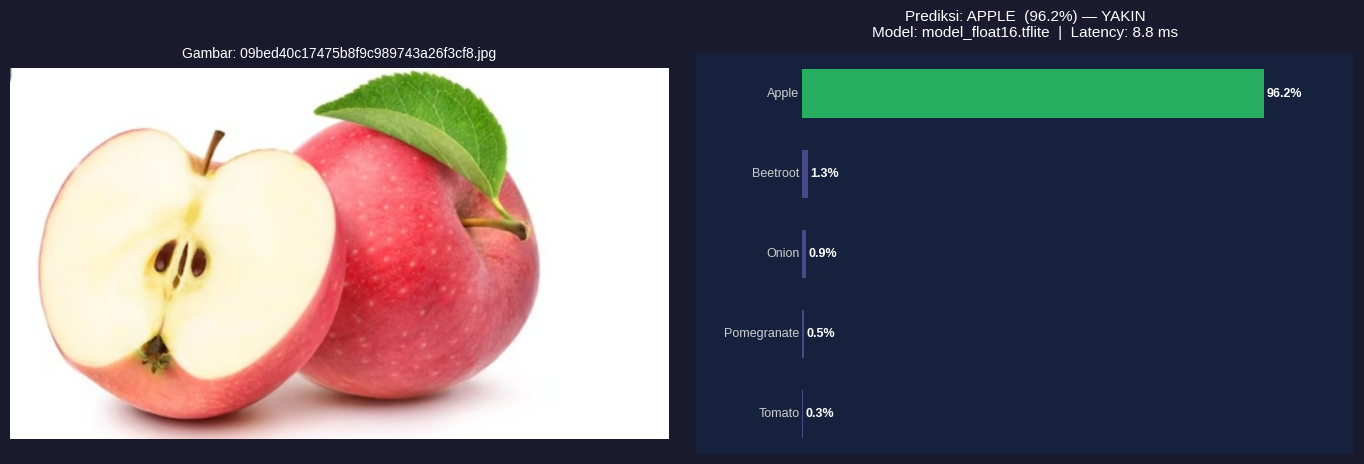


Testing selesai! Jalankan cell ini lagi untuk upload gambar baru.


In [ ]:
# ══════════════════════════════════════════════════════
# CELL 2 — Upload gambar & predict
#           Bisa pilih banyak gambar sekaligus!
# ══════════════════════════════════════════════════════

print("Pilih gambar dari device kamu (jpg/png)...")
print("Bisa pilih lebih dari satu gambar sekaligus!\n")

uploaded = files.upload()

if not uploaded:
    print("Tidak ada gambar yang diupload.")
else:
    print(f"Memproses {len(uploaded)} gambar...\n")
    print("=" * 60)

    all_results = []

    for filename, file_bytes in uploaded.items():
        try:
            img_pil = Image.open(io.BytesIO(file_bytes))
            results, latency = run_inference(img_pil)
            show_result(img_pil, results, latency, filename)
            all_results.append({
                "file"      : filename,
                "prediksi"  : results[0][0],
                "confidence": round(results[0][1], 2),
                "latency_ms": round(latency, 1),
                "top5"      : [{"label": r[0], "conf": round(r[1], 2)} for r in results]
            })
        except Exception as e:
            print(f"Error pada {filename}: {e}")

    # Tabel ringkasan jika lebih dari 1 gambar
    if len(all_results) > 1:
        print("\n" + "=" * 65)
        print(f"  RINGKASAN — {len(all_results)} Gambar")
        print("=" * 65)
        header = f"{'No':<4} {'File':<28} {'Prediksi':<24} {'Conf':>6} {'Latency':>10}"
        print(header)
        print("-" * 65)
        for i, r in enumerate(all_results, 1):
            flag = "[OK]" if r["confidence"] >= 70 else "[?] " if r["confidence"] >= 40 else "[X] "
            nama = (r["file"][:26] + "..") if len(r["file"]) > 28 else r["file"]
            pred = (r["prediksi"][:22] + "..") if len(r["prediksi"]) > 24 else r["prediksi"]
            print(f"{i:<4} {nama:<28} {flag} {pred:<22} {r['confidence']:>5.1f}%  {r['latency_ms']:>6.1f} ms")
        print("-" * 65)
        avg_lat  = sum(r["latency_ms"]  for r in all_results) / len(all_results)
        avg_conf = sum(r["confidence"]  for r in all_results) / len(all_results)
        high     = sum(1 for r in all_results if r["confidence"] >= 70)
        print(f"  Avg confidence  : {avg_conf:.1f}%")
        print(f"  Avg latency     : {avg_lat:.1f} ms/gambar")
        print(f"  High conf (>=70%): {high}/{len(all_results)}")
        print("=" * 65)

    print("\nTesting selesai! Jalankan cell ini lagi untuk upload gambar baru.")
